# Glacial Lake Segmentation — ResNet34-FCN Baseline (Google Colab Training)

[![Python 3.9+](https://img.shields.io/badge/Python-3.9%2B-blue.svg)](https://www.python.org/)
[![PyTorch 2.0+](https://img.shields.io/badge/PyTorch-2.0%2B-ee4c2c.svg)](https://pytorch.org/)
[![Dataset: GLID](https://img.shields.io/badge/Dataset-GLID-green.svg)](https://doi.org/10.5281/zenodo.14838695)

This notebook is the **dedicated, reproducible Google Colab training, checkpointing, and evaluation environment** for the **ResNet-34 Fully Convolutional Network (FCN)** baseline model.

---

### Architectural Specifications
* **Encoder**: ResNet-34 convolutional backbone initialized with ImageNet pretrained weights (`ResNet34_Weights.DEFAULT`).
* **Decoder**: 5-stage progressive transposed-convolution upsampling head ($512 \to 256 \to 128 \to 64 \to 32 \to 16 \to 1$) with Batch Normalization and ReLU activations.
* **Exact Parameters**: **24,079,153 total parameters** (21,284,672 encoder + 2,794,481 decoder; 100% trainable, 0 non-trainable).
* **Comparison Model**: DeepLabV3+ with ResNet-50 + ASPP (**40,347,041 total parameters**).

---

### Key Operational Safeguards
1. **Isolated Google Drive Experiment Folder**: Checkpoints, logs, training curves, evaluation metrics, and comparison summaries are saved in:
   `Glacial_Lake_Segmentation/experiments/resnet34_fcn_colab/` (completely isolated from DeepLabV3+ files).
2. **Explicit Multi-Candidate Dataset Selection**: Scans Google Drive, displays all candidate paths and sample counts, avoids auto-selecting `test` folders as validation, and requires an explicit unambiguous match.
3. **Reusable Archive Transfer, Local SSD Extraction & Integrity Checks**: Confirms matching image-label filenames, validates readability on sample pairs, and creates a reusable Drive archive once, extracts to local SSD with progress, and verifies cache metadata; source data is never deleted.
4. **Zero Weight-Mutation Speed Benchmark**: Benchmarks GPU throughput on an isolated temporary model instance, programmatically asserting that training model weights remain 100% untouched.
5. **Atomic Checkpointing & CSV-History Sync**: Checkpoint payload and CSV history are strictly synchronized upon resume, preventing duplicate or skipped epoch records after Colab disconnections.
6. **Optional Smoke Test Mode**: An isolated 1-epoch mini smoke-test verifies forward pass, loss computation, atomic checkpoint saving, checkpoint reload, and evaluation without modifying primary weights.

> **Hardware Requirement**: Ensure GPU acceleration is enabled via **Runtime → Change runtime type → T4 GPU** (or A100/V100).


## 1. Hardware & Environment Verification
Verify CUDA availability, GPU device specifications, and runtime memory.


In [28]:
# 1.1 GPU and CUDA Verification
import sys
import torch

print("=" * 65)
print("  Environment & Hardware Verification")
print("=" * 65)
print(f"Python Version    : {sys.version.split()[0]}")
print(f"PyTorch Version   : {torch.__version__}")
print(f"CUDA Available    : {torch.cuda.is_available()}")

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA GPU is not detected!\n"
        "Please navigate to: Runtime -> Change runtime type -> Hardware accelerator -> T4 GPU"
    )

gpu_name = torch.cuda.get_device_name(0)
gpu_mem_gb = torch.cuda.get_device_properties(0).total_memory / (1024**3)
print(f"GPU Model         : {gpu_name}")
print(f"GPU VRAM          : {gpu_mem_gb:.2f} GB")
print(f"CUDA Device Count : {torch.cuda.device_count()}")
print("=" * 65)

# Enable cuDNN benchmark for optimized conv kernels with fixed 512x512 inputs
torch.backends.cudnn.benchmark = True


  Environment & Hardware Verification
Python Version    : 3.13.15
PyTorch Version   : 2.11.0+cu130
CUDA Available    : True
GPU Model         : Tesla T4
GPU VRAM          : 14.56 GB
CUDA Device Count : 1


## 2. Google Drive Mounting & Repository Setup
Mount Google Drive and clone or pull the latest project source code.


In [29]:
# 2.1 Mount Google Drive
from google.colab import drive
import os

drive.mount('/content/drive')
print("✓ Google Drive mounted successfully.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✓ Google Drive mounted successfully.


In [30]:
# 2.2 Clone or update project repository
from pathlib import Path

%cd /content
REPO_DIR = Path("/content/glacial-lake-segmentation")
REPO_URL = "https://github.com/ShubhamSnSharma/glacial-lake-segmentation.git"

if not REPO_DIR.exists():
    print(f"Cloning repository from {REPO_URL}...")
    !git clone -q {REPO_URL}
else:
    print("Repository exists locally. Pulling latest commits from main...")
    %cd {REPO_DIR}
    !git pull -q

%cd {REPO_DIR}
!git log -1 --oneline
print("✓ Working directory set to:", os.getcwd())


/content
Repository exists locally. Pulling latest commits from main...
/content/glacial-lake-segmentation
/content/glacial-lake-segmentation
1ff3d4a (HEAD -> main, origin/main, origin/HEAD) Fix speed benchmark isolation, robust dataset discovery, and verify parameter counts
✓ Working directory set to: /content/glacial-lake-segmentation


In [31]:
# 2.3 Install project dependencies and restore repository imports

import sys
import subprocess
from pathlib import Path

REPO_DIR = Path("/content/glacial-lake-segmentation")

if not REPO_DIR.exists():
    raise FileNotFoundError(
        f"Repository not found: {REPO_DIR}. "
        "Run cell 2.2 first."
    )

# Set repository root as the working directory
%cd /content/glacial-lake-segmentation

# Register repository root for imports such as `from src.dataset import GLIDDataset`
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

# Install only the supporting packages.
# Do not reinstall or replace Colab's PyTorch/CUDA build.
packages = [
    "pillow",
    "pyyaml",
    "matplotlib",
    "tqdm",
    "scikit-learn",
    "pandas"
]

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q", *packages
])

# Verify that the repository imports work
from src.dataset import GLIDDataset

print("✓ Repository path restored.")
print("✓ GLIDDataset imported successfully.")
print("✓ Supporting dependencies installed.")
print("Repository:", REPO_DIR)

/content/glacial-lake-segmentation
✓ Repository path restored.
✓ GLIDDataset imported successfully.
✓ Supporting dependencies installed.
Repository: /content/glacial-lake-segmentation


## 3. Directory Configuration & Dataset Discovery
Configure experiment directories, search Google Drive for GLID splits, and require explicit unambiguous dataset selection.


In [32]:
# 3.1 Path Configuration & Isolated Output Directories
from pathlib import Path

# Base Google Drive root for the project
DRIVE_PROJECT_ROOT = Path("/content/drive/MyDrive/Glacial_Lake_Segmentation")

# Dedicated experiment folder for ResNet34-FCN
EXP_DIR = DRIVE_PROJECT_ROOT / "experiments" / "resnet34_fcn_colab"
EXP_CHECKPOINTS = EXP_DIR / "checkpoints"
EXP_RESULTS = EXP_DIR / "results"
EXP_LOGS = EXP_RESULTS / "logs"
EXP_PLOTS = EXP_RESULTS / "plots"
EXP_PREDICTIONS = EXP_RESULTS / "predictions"
EXP_EVALUATION = EXP_RESULTS / "evaluation"
EXP_COMPARISON = EXP_DIR / "comparison"
EXP_SMOKE_TEST = EXP_DIR / "smoke_test"

# Create all persistent experiment directories in Drive
for folder in [EXP_CHECKPOINTS, EXP_LOGS, EXP_PLOTS, EXP_PREDICTIONS, EXP_EVALUATION, EXP_COMPARISON, EXP_SMOKE_TEST]:
    folder.mkdir(parents=True, exist_ok=True)

# Local fast NVMe SSD storage path
LOCAL_DATA_ROOT = Path("/content/dataset")
LOCAL_TRAIN_DIR = LOCAL_DATA_ROOT / "GLID"
LOCAL_VAL_DIR = LOCAL_DATA_ROOT / "val"

print("✓ Experiment output paths initialized:")
print(f"  Checkpoints : {EXP_CHECKPOINTS}")
print(f"  Logs        : {EXP_LOGS}")
print(f"  Evaluation  : {EXP_EVALUATION}")


✓ Experiment output paths initialized:
  Checkpoints : /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/resnet34_fcn_colab/checkpoints
  Logs        : /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/resnet34_fcn_colab/results/logs
  Evaluation  : /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/resnet34_fcn_colab/results/evaluation


In [33]:
# 3.2 Robust Multi-Path Google Drive Dataset Discovery & Explicit Selection
import os
import re
from typing import List, Tuple, Optional

# Set to True ONLY if you explicitly wish to consider directories named 'test' as validation
ALLOW_TEST_AS_VAL = False

# Optional explicit paths; auto-selection only when exactly one candidate exists.
DRIVE_TRAIN_SRC = None
DRIVE_VAL_SRC = None

def scan_for_dataset_splits(
    search_roots: List[Path],
    allow_test_as_val: bool = False
) -> Tuple[List[Path], List[Path]]:
    """
    Recursively scans search roots for valid GLID training and validation directories.
    A valid directory must contain image and label subdirectories with .png files.
    """
    IMG_CANDIDATES = {"images", "image", "img"}
    LBL_CANDIDATES = {"labels", "label", "masks", "mask", "annotation"}

    def check_split_dir(p: Path) -> bool:
        if not p.is_dir():
            return False
        subdirs = {d.name.lower() for d in p.iterdir() if d.is_dir()}
        has_img = bool(subdirs & IMG_CANDIDATES)
        has_lbl = bool(subdirs & LBL_CANDIDATES)
        if not (has_img and has_lbl):
            return False
        # Ensure non-empty png files exist
        img_sub = next(p / d for d in p.iterdir() if d.name.lower() in IMG_CANDIDATES)
        return any(f.suffix.lower() == ".png" for f in img_sub.glob("*.png"))

    train_found, val_found = [], []

    for root in search_roots:
        if not root.exists():
            continue
        for dirpath, dirnames, _ in os.walk(root):
            p = Path(dirpath)
            # Exclude unwanted directories
            dirnames[:] = [d for d in dirnames if not d.startswith(".") and d not in ["__pycache__", "experiments", "results", "checkpoints", "plots", "logs"]]
            if check_split_dir(p):
                name_lower = p.name.lower()
                if any(k in name_lower for k in ["glid", "train", "training"]):
                    if p not in train_found:
                        train_found.append(p)
                elif any(k in name_lower for k in ["val", "validation"]):
                    if p not in val_found:
                        val_found.append(p)
                elif allow_test_as_val and "test" in name_lower:
                    if p not in val_found:
                        val_found.append(p)

    return train_found, val_found

CANDIDATE_SEARCH_ROOTS = [
    DRIVE_PROJECT_ROOT,
    Path("/content/drive/MyDrive/GLID_dataset"),
    Path("/content/drive/MyDrive/GLID"),
    Path("/content/drive/MyDrive")
]

print("Scanning Google Drive for GLID dataset directories...")
discovered_train, discovered_val = scan_for_dataset_splits(
    CANDIDATE_SEARCH_ROOTS,
    allow_test_as_val=ALLOW_TEST_AS_VAL
)

print("\n" + "=" * 65)
print("  Discovered Dataset Candidates in Google Drive")
print("=" * 65)
print("Training Candidates:")
for idx, p in enumerate(discovered_train):
    print(f"  [{idx}] {p}")
if not discovered_train:
    print("  (None found)")

print("\nValidation Candidates:")
for idx, p in enumerate(discovered_val):
    print(f"  [{idx}] {p}")
if not discovered_val:
    print("  (None found)")
print("=" * 65)

if not discovered_train or not discovered_val:
    raise FileNotFoundError(
        "Could not automatically locate GLID training and validation directories in Google Drive.\n\n"
        "Expected directory structure in Drive:\n"
        "  MyDrive/Glacial_Lake_Segmentation/GLID/images/  and  labels/\n"
        "  MyDrive/Glacial_Lake_Segmentation/val/images/   and  labels/\n\n"
        "If your dataset is located elsewhere, please set `DRIVE_TRAIN_SRC` and `DRIVE_VAL_SRC` manually."
    )

# Refuse ambiguity rather than silently selecting a candidate.
if DRIVE_TRAIN_SRC is None:
    if len(discovered_train) != 1:
        raise RuntimeError(f"Found {len(discovered_train)} training candidates. Set DRIVE_TRAIN_SRC explicitly and rerun.")
    DRIVE_TRAIN_SRC = discovered_train[0]
else:
    DRIVE_TRAIN_SRC = Path(DRIVE_TRAIN_SRC)
    if DRIVE_TRAIN_SRC not in discovered_train: raise ValueError(f"Invalid training path: {DRIVE_TRAIN_SRC}")
if DRIVE_VAL_SRC is None:
    if len(discovered_val) != 1:
        raise RuntimeError(f"Found {len(discovered_val)} validation candidates. Set DRIVE_VAL_SRC explicitly and rerun.")
    DRIVE_VAL_SRC = discovered_val[0]
else:
    DRIVE_VAL_SRC = Path(DRIVE_VAL_SRC)
    if DRIVE_VAL_SRC not in discovered_val: raise ValueError(f"Invalid validation path: {DRIVE_VAL_SRC}")
if DRIVE_TRAIN_SRC == DRIVE_VAL_SRC: raise ValueError("Train and validation paths must differ.")

print(f"\n✓ Confirmed Training Source   : {DRIVE_TRAIN_SRC}")
print(f"✓ Confirmed Validation Source : {DRIVE_VAL_SRC}")


Scanning Google Drive for GLID dataset directories...

  Discovered Dataset Candidates in Google Drive
Training Candidates:
  [0] /content/drive/MyDrive/Glacial_Lake_Segmentation/GLID

Validation Candidates:
  [0] /content/drive/MyDrive/Glacial_Lake_Segmentation/val

✓ Confirmed Training Source   : /content/drive/MyDrive/Glacial_Lake_Segmentation/GLID
✓ Confirmed Validation Source : /content/drive/MyDrive/Glacial_Lake_Segmentation/val


In [34]:
# 3.3 Resumable Dataset Archiving and Local SSD Extraction
#
# CPU is sufficient for this entire cell.
# Original Google Drive source folders remain untouched.
# Completed archive chunks survive runtime resets.
#
# IMPORTANT:
#   The raw GLID folders contain some duplicate/orphan download artifacts.
#   These are NOT treated as fatal errors here.
#   Only matched image-mask pairs are considered valid.
#   Cell 3.3B creates the final clean matched-pair dataset view.

import os
import sys
import json
import time
import shutil
import zipfile
from pathlib import Path

import numpy as np
from PIL import Image
from tqdm.auto import tqdm


# Restore repository imports in case this cell is run independently
REPO_DIR = Path("/content/glacial-lake-segmentation")

if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))


# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

CHUNK_SIZE = 500

# Keep False so existing verified archive chunks are reused.
FORCE_REBUILD_ARCHIVE = False

# Keep False so an existing verified local cache is reused.
FORCE_REEXTRACT_CACHE = False

# Expected valid matched-pair counts.
EXPECTED_TRAIN_PAIRS = 16000
EXPECTED_VAL_PAIRS = 2367


ARCHIVE_DIR = DRIVE_PROJECT_ROOT / "dataset_archives"
ARCHIVE_DIR.mkdir(parents=True, exist_ok=True)

CHUNK_DIR = ARCHIVE_DIR / "glid_chunks_v1"
CHUNK_DIR.mkdir(parents=True, exist_ok=True)

MANIFEST_PATH = ARCHIVE_DIR / "glid_chunks_manifest_v1.json"

STAGING_ROOT = Path("/content/glid_extract_staging")

CACHE_META_PATH = LOCAL_DATA_ROOT / ".cache_meta.json"


print("=" * 70)
print("RESUMABLE GLID DATASET ARCHIVE & LOCAL CACHE")
print("=" * 70)
print("Archive directory :", CHUNK_DIR)
print("Chunk size        :", CHUNK_SIZE)
print("Expected train    :", f"{EXPECTED_TRAIN_PAIRS:,} matched pairs")
print("Expected val      :", f"{EXPECTED_VAL_PAIRS:,} matched pairs")
print("=" * 70)


# ------------------------------------------------------------
# 2. DATASET DIRECTORY HELPERS
# ------------------------------------------------------------

def find_split_dirs(split_dir):
    """
    Locate image and label directories inside a dataset split.
    """

    image_names = ("images", "image", "img")
    label_names = ("labels", "label", "masks", "mask", "annotation")

    img_dir = next(
        (
            split_dir / name
            for name in image_names
            if (split_dir / name).is_dir()
        ),
        None
    )

    lbl_dir = next(
        (
            split_dir / name
            for name in label_names
            if (split_dir / name).is_dir()
        ),
        None
    )

    if img_dir is None or lbl_dir is None:
        raise FileNotFoundError(
            f"Image/label directories not found in {split_dir}"
        )

    return img_dir, lbl_dir


def get_png_files(split_dir):
    """
    Recursively collect PNG files from a dataset split.
    """

    files = sorted(
        p
        for p in split_dir.rglob("*.png")
        if p.is_file() and not p.name.startswith(".")
    )

    if not files:
        raise FileNotFoundError(
            f"No PNG files found in {split_dir}"
        )

    return files


def verify_split_integrity(
    split_dir,
    split_name,
    n_samples_to_test=8
):
    """
    Verify the usable image-mask pairs.

    IMPORTANT:
    Orphan/duplicate download artifacts are reported but are NOT
    treated as fatal errors. The clean matched-pair dataset is
    created later by Cell 3.3B.

    Returns:
        Number of matched image-mask pairs.
    """

    img_dir, lbl_dir = find_split_dirs(split_dir)

    img_files = {
        p.name: p
        for p in img_dir.glob("*.png")
        if not p.name.startswith(".")
    }

    lbl_files = {
        p.name: p
        for p in lbl_dir.glob("*.png")
        if not p.name.startswith(".")
    }

    common = set(img_files) & set(lbl_files)

    orphan_images = set(img_files) - common
    orphan_labels = set(lbl_files) - common

    print("\n" + "=" * 70)
    print(f"Integrity check: {split_name}")
    print("=" * 70)

    print("Images          :", f"{len(img_files):,}")
    print("Labels          :", f"{len(lbl_files):,}")
    print("Matched pairs   :", f"{len(common):,}")
    print("Orphan images   :", f"{len(orphan_images):,}")
    print("Orphan labels   :", f"{len(orphan_labels):,}")

    if not common:
        raise ValueError(
            f"No matched image-mask pairs found in {split_dir}"
        )

    if orphan_images or orphan_labels:
        print(
            "\n⚠ Orphan/duplicate files detected."
            "\n  These files will NOT be used by the clean dataset."
            "\n  Cell 3.3B will retain only matched image-mask pairs."
        )
    else:
        print("\n✓ No orphan files detected.")

    # --------------------------------------------------------
    # Validate a sample of matched pairs.
    # --------------------------------------------------------

    test_names = sorted(common)[
        :min(n_samples_to_test, len(common))
    ]

    for name in test_names:

        # Validate image
        with Image.open(img_files[name]) as image:

            if image.size != (512, 512):
                raise ValueError(
                    f"Invalid image dimensions: {name} "
                    f"-> {image.size}"
                )

            image.verify()

        # Validate mask
        with Image.open(lbl_files[name]) as mask:

            if mask.size != (512, 512):
                raise ValueError(
                    f"Invalid mask dimensions: {name} "
                    f"-> {mask.size}"
                )

            values = set(
                np.unique(np.asarray(mask)).tolist()
            )

            if not values.issubset({0, 255}):
                raise ValueError(
                    f"Unexpected mask values in {name}: {values}"
                )

    print("✓ Matched-pair sample validation passed.")

    return len(common)


# ------------------------------------------------------------
# 3. DISCOVER SOURCE FILES
# ------------------------------------------------------------

source_splits = {
    "GLID": DRIVE_TRAIN_SRC,
    "val": DRIVE_VAL_SRC
}

split_files = {}

for split_name, split_path in source_splits.items():

    if not split_path.is_dir():
        raise FileNotFoundError(
            f"Missing source directory: {split_path}"
        )

    split_files[split_name] = get_png_files(split_path)

    print(
        f"{split_name}: "
        f"{len(split_files[split_name]):,} PNG files"
    )

total_files = sum(
    len(files)
    for files in split_files.values()
)

print(
    f"\nTotal files to archive: "
    f"{total_files:,}"
)


# ------------------------------------------------------------
# 4. LOAD OR INITIALIZE ARCHIVE MANIFEST
# ------------------------------------------------------------

expected_manifest = {
    "version": 1,
    "chunk_size": CHUNK_SIZE,

    "sources": {
        name: str(path)
        for name, path in source_splits.items()
    },

    "file_counts": {
        name: len(files)
        for name, files in split_files.items()
    }
}

manifest = None


if (
    MANIFEST_PATH.exists()
    and not FORCE_REBUILD_ARCHIVE
):

    try:

        with open(
            MANIFEST_PATH,
            encoding="utf-8"
        ) as f:

            manifest = json.load(f)

        manifest_matches = (
            manifest.get("version")
            == expected_manifest["version"]
            and
            manifest.get("chunk_size")
            == CHUNK_SIZE
            and
            manifest.get("sources")
            == expected_manifest["sources"]
            and
            manifest.get("file_counts")
            == expected_manifest["file_counts"]
        )

        if not manifest_matches:

            print(
                "\nManifest configuration changed."
                "\nExisting archive will be rebuilt."
            )

            manifest = None

        else:

            print(
                "\n✓ Existing archive manifest matches "
                "current dataset."
            )

    except (
        OSError,
        json.JSONDecodeError
    ):

        print(
            "\n⚠ Existing manifest could not be read."
            "\nA new manifest will be created."
        )

        manifest = None


if manifest is None:

    manifest = {
        **expected_manifest,
        "completed_chunks": {}
    }

    with open(
        MANIFEST_PATH,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            manifest,
            f,
            indent=2
        )

    print("✓ Archive manifest initialized.")


# ------------------------------------------------------------
# 5. BUILD RESUMABLE ARCHIVE CHUNKS
# ------------------------------------------------------------

def chunk_path(split_name, chunk_index):

    return (
        CHUNK_DIR
        / f"{split_name}_{chunk_index:05d}.zip"
    )


def chunk_is_valid(path):

    if (
        not path.is_file()
        or path.stat().st_size == 0
    ):
        return False

    try:

        with zipfile.ZipFile(
            path,
            "r"
        ) as zf:

            return zf.testzip() is None

    except (
        OSError,
        zipfile.BadZipFile
    ):

        return False


def save_manifest():

    temp = MANIFEST_PATH.with_suffix(".tmp")

    with open(
        temp,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            manifest,
            f,
            indent=2
        )

    temp.replace(MANIFEST_PATH)


for split_name, files in split_files.items():

    n_chunks = (
        len(files)
        + CHUNK_SIZE
        - 1
    ) // CHUNK_SIZE

    for chunk_index in range(n_chunks):

        start = (
            chunk_index
            * CHUNK_SIZE
        )

        end = min(
            start + CHUNK_SIZE,
            len(files)
        )

        final_zip = chunk_path(
            split_name,
            chunk_index
        )

        temp_zip = final_zip.with_suffix(
            ".building"
        )

        chunk_key = (
            f"{split_name}_"
            f"{chunk_index:05d}"
        )

        recorded = (
            manifest["completed_chunks"]
            .get(chunk_key)
        )

        # ----------------------------------------------------
        # Reuse an already completed chunk.
        # ----------------------------------------------------

        if (
            not FORCE_REBUILD_ARCHIVE
            and recorded
            and final_zip.exists()
            and final_zip.stat().st_size
            == recorded.get("size")
            and chunk_is_valid(final_zip)
        ):

            print(
                f"✓ Reusing {chunk_key}"
            )

            continue

        # ----------------------------------------------------
        # Remove incomplete temporary archive.
        # ----------------------------------------------------

        if temp_zip.exists():
            temp_zip.unlink()

        chunk_files = files[start:end]

        print(
            f"\nBuilding {chunk_key}: "
            f"{start + 1:,}-{end:,} "
            f"of {len(files):,}"
        )

        with zipfile.ZipFile(
            temp_zip,
            "w",
            compression=zipfile.ZIP_STORED,
            allowZip64=True
        ) as zf:

            for file_path in tqdm(
                chunk_files,
                desc=chunk_key,
                unit="file"
            ):

                relative = (
                    file_path.relative_to(
                        source_splits[
                            split_name
                        ]
                    )
                )

                arcname = (
                    Path(split_name)
                    / relative
                )

                zf.write(
                    file_path,
                    arcname.as_posix()
                )

        # ----------------------------------------------------
        # Verify before publishing.
        # ----------------------------------------------------

        if not chunk_is_valid(temp_zip):

            raise RuntimeError(
                f"Chunk verification failed: "
                f"{chunk_key}"
            )

        temp_zip.replace(final_zip)

        manifest[
            "completed_chunks"
        ][chunk_key] = {

            "size": final_zip.stat().st_size,

            "files": len(chunk_files)
        }

        save_manifest()

        print(
            f"✓ Saved completed chunk: "
            f"{chunk_key}"
        )


print(
    "\n✓ All archive chunks are complete."
)

print(
    "Manifest:",
    MANIFEST_PATH
)


# ------------------------------------------------------------
# 6. VERIFY COMPLETED CHUNK INVENTORY
# ------------------------------------------------------------

chunk_paths = []

for split_name, files in split_files.items():

    n_chunks = (
        len(files)
        + CHUNK_SIZE
        - 1
    ) // CHUNK_SIZE

    for chunk_index in range(n_chunks):

        path = chunk_path(
            split_name,
            chunk_index
        )

        if not chunk_is_valid(path):

            raise RuntimeError(
                f"Missing or invalid chunk: "
                f"{path}"
            )

        chunk_paths.append(path)


print(
    f"✓ Verified {len(chunk_paths)} "
    f"archive chunks."
)


# ------------------------------------------------------------
# 7. CHECK EXISTING LOCAL CACHE
# ------------------------------------------------------------

LOCAL_DATA_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

cache_ok = False

if (
    not FORCE_REEXTRACT_CACHE
    and LOCAL_TRAIN_DIR.is_dir()
    and LOCAL_VAL_DIR.is_dir()
    and CACHE_META_PATH.is_file()
):

    try:

        with open(
            CACHE_META_PATH,
            encoding="utf-8"
        ) as f:

            cache_meta = json.load(f)

        cache_ok = (
            cache_meta.get("complete")
            is True

            and
            cache_meta.get("manifest_version")
            == 1

            and
            cache_meta.get("total_chunks")
            == len(chunk_paths)

            and
            cache_meta.get("train_pairs")
            == EXPECTED_TRAIN_PAIRS

            and
            cache_meta.get("val_pairs")
            == EXPECTED_VAL_PAIRS
        )

    except (
        OSError,
        json.JSONDecodeError
    ):

        cache_ok = False


# ------------------------------------------------------------
# 8. EXTRACT ARCHIVE TO LOCAL SSD
# ------------------------------------------------------------

if not cache_ok:

    print(
        "\nPreparing local SSD cache..."
    )

    start_time = time.time()

    # Remove previous incomplete staging.
    if STAGING_ROOT.exists():
        shutil.rmtree(STAGING_ROOT)

    STAGING_ROOT.mkdir(
        parents=True,
        exist_ok=True
    )

    # --------------------------------------------------------
    # Extract all archive chunks.
    # --------------------------------------------------------

    for archive in tqdm(
        chunk_paths,
        desc="Extracting archive chunks",
        unit="chunk"
    ):

        with zipfile.ZipFile(
            archive,
            "r"
        ) as zf:

            zf.extractall(
                STAGING_ROOT
            )

    staged_train = (
        STAGING_ROOT / "GLID"
    )

    staged_val = (
        STAGING_ROOT / "val"
    )

    # --------------------------------------------------------
    # Validate matched-pair counts.
    #
    # Orphans are allowed here because Cell 3.3B removes
    # them from the clean dataset view.
    # --------------------------------------------------------

    n_train_stage = verify_split_integrity(
        staged_train,
        "staged training"
    )

    n_val_stage = verify_split_integrity(
        staged_val,
        "staged validation"
    )

    if (
        n_train_stage
        != EXPECTED_TRAIN_PAIRS
        or
        n_val_stage
        != EXPECTED_VAL_PAIRS
    ):

        raise ValueError(
            "Unexpected matched-pair counts: "
            f"train={n_train_stage:,}, "
            f"val={n_val_stage:,}"
        )

    print(
        "\n✓ Expected matched-pair counts "
        "confirmed:"
    )

    print(
        f"  Training   : {n_train_stage:,}"
    )

    print(
        f"  Validation : {n_val_stage:,}"
    )

    # --------------------------------------------------------
    # Publish local cache.
    # --------------------------------------------------------

    backups = []

    try:

        for destination, staged in (
            (
                LOCAL_TRAIN_DIR,
                staged_train
            ),
            (
                LOCAL_VAL_DIR,
                staged_val
            )
        ):

            backup = destination.with_name(
                destination.name
                + ".previous"
            )

            if backup.exists():
                shutil.rmtree(backup)

            if destination.exists():

                destination.replace(
                    backup
                )

                backups.append(
                    (
                        destination,
                        backup
                    )
                )

            staged.replace(
                destination
            )

        # ----------------------------------------------------
        # Write completion metadata only after successful
        # publication.
        # ----------------------------------------------------

        temp_meta = (
            CACHE_META_PATH
            .with_suffix(".tmp")
        )

        with open(
            temp_meta,
            "w",
            encoding="utf-8"
        ) as f:

            json.dump(
                {
                    "manifest_version": 1,
                    "total_chunks": len(
                        chunk_paths
                    ),
                    "cached_at": time.strftime(
                        "%Y-%m-%d %H:%M:%S"
                    ),
                    "complete": True,
                    "train_pairs":
                        n_train_stage,
                    "val_pairs":
                        n_val_stage
                },
                f,
                indent=2
            )

        temp_meta.replace(
            CACHE_META_PATH
        )

    except Exception:

        # Restore previous cache if publication failed.

        for (
            destination,
            backup
        ) in reversed(backups):

            if destination.exists():
                shutil.rmtree(
                    destination
                )

            if backup.exists():
                backup.replace(
                    destination
                )

        raise

    # --------------------------------------------------------
    # Remove old backups only after successful publication.
    # --------------------------------------------------------

    for _, backup in backups:

        if backup.exists():
            shutil.rmtree(backup)

    print(
        f"\n✓ Local cache prepared in "
        f"{(time.time() - start_time) / 60:.1f} minutes."
    )

else:

    print(
        "\n✓ Existing verified local cache reused."
    )


# ------------------------------------------------------------
# 9. MAKE STAGING_ROOT AVAILABLE FOR CELL 3.3B
# ------------------------------------------------------------
#
# Cell 3.3B intentionally works from STAGING_ROOT so that it
# can construct the clean matched-pair dataset without
# modifying the original/local cached data.
#
# If the cache was reused, recreate a lightweight staging view
# using symlinks instead of copying the dataset again.
# ------------------------------------------------------------

if STAGING_ROOT.exists():
    shutil.rmtree(STAGING_ROOT)

STAGING_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

staging_train_link = (
    STAGING_ROOT / "GLID"
)

staging_val_link = (
    STAGING_ROOT / "val"
)

staging_train_link.symlink_to(
    LOCAL_TRAIN_DIR,
    target_is_directory=True
)

staging_val_link.symlink_to(
    LOCAL_VAL_DIR,
    target_is_directory=True
)

print(
    "✓ Staging view ready for Cell 3.3B."
)

print(
    "  Training source :",
    staging_train_link
)

print(
    "  Validation source:",
    staging_val_link
)


# ------------------------------------------------------------
# 10. FINAL MATCHED-PAIR VERIFICATION
# ------------------------------------------------------------

n_train_verified = verify_split_integrity(
    LOCAL_TRAIN_DIR,
    "final training cache"
)

n_val_verified = verify_split_integrity(
    LOCAL_VAL_DIR,
    "final validation cache"
)

if (
    n_train_verified
    != EXPECTED_TRAIN_PAIRS
    or
    n_val_verified
    != EXPECTED_VAL_PAIRS
):

    raise ValueError(
        "Final matched-pair verification failed: "
        f"train={n_train_verified:,}, "
        f"val={n_val_verified:,}"
    )


# ------------------------------------------------------------
# 11. FINAL STATUS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RESUMABLE DATASET ARCHIVE & CACHE READY")
print("=" * 70)

print(
    f"Training matched pairs   : "
    f"{n_train_verified:,}"
)

print(
    f"Validation matched pairs : "
    f"{n_val_verified:,}"
)

print(
    "Original Drive data      : untouched"
)

print(
    "Archive chunks            : persistent"
)

print(
    "Local SSD cache           : verified"
)

print(
    "Clean dataset next        : Cell 3.3B"
)

print("=" * 70)

RESUMABLE GLID DATASET ARCHIVE & LOCAL CACHE
Archive directory : /content/drive/MyDrive/Glacial_Lake_Segmentation/dataset_archives/glid_chunks_v1
Chunk size        : 500
Expected train    : 16,000 matched pairs
Expected val      : 2,367 matched pairs
GLID: 32,121 PNG files
val: 4,799 PNG files

Total files to archive: 36,920

✓ Existing archive manifest matches current dataset.
✓ Reusing GLID_00000
✓ Reusing GLID_00001
✓ Reusing GLID_00002
✓ Reusing GLID_00003
✓ Reusing GLID_00004
✓ Reusing GLID_00005
✓ Reusing GLID_00006
✓ Reusing GLID_00007
✓ Reusing GLID_00008
✓ Reusing GLID_00009
✓ Reusing GLID_00010
✓ Reusing GLID_00011
✓ Reusing GLID_00012
✓ Reusing GLID_00013
✓ Reusing GLID_00014
✓ Reusing GLID_00015
✓ Reusing GLID_00016
✓ Reusing GLID_00017
✓ Reusing GLID_00018
✓ Reusing GLID_00019
✓ Reusing GLID_00020
✓ Reusing GLID_00021
✓ Reusing GLID_00022
✓ Reusing GLID_00023
✓ Reusing GLID_00024
✓ Reusing GLID_00025
✓ Reusing GLID_00026
✓ Reusing GLID_00027
✓ Reusing GLID_00028
✓ Reusing 

In [35]:
# 3.3A — Diagnose unmatched files
# CPU ONLY — does not modify or delete anything.

from pathlib import Path
from collections import Counter
import re

staged_train = STAGING_ROOT / "GLID"
staged_val = STAGING_ROOT / "val"

def diagnose_split(split_dir, split_name):
    img_dir = split_dir / "images"
    lbl_dir = split_dir / "labels"

    img_names = {
        p.name for p in img_dir.glob("*.png")
        if not p.name.startswith(".")
    }

    lbl_names = {
        p.name for p in lbl_dir.glob("*.png")
        if not p.name.startswith(".")
    }

    matched = sorted(img_names & lbl_names)
    orphan_images = sorted(img_names - lbl_names)
    orphan_labels = sorted(lbl_names - img_names)

    print("\n" + "=" * 75)
    print(f"{split_name.upper()} DATASET DIAGNOSTIC")
    print("=" * 75)

    print(f"Images          : {len(img_names):,}")
    print(f"Labels          : {len(lbl_names):,}")
    print(f"Matched pairs   : {len(matched):,}")
    print(f"Orphan images   : {len(orphan_images):,}")
    print(f"Orphan labels   : {len(orphan_labels):,}")

    print("\n--- Orphan image examples ---")
    for x in orphan_images[:30]:
        print(" ", x)

    print("\n--- Orphan label examples ---")
    for x in orphan_labels[:30]:
        print(" ", x)

    # Detect common duplicate/download naming patterns
    duplicate_patterns = []

    for name in orphan_images + orphan_labels:
        stem = Path(name).stem

        if re.search(r"\s*\(\d+\)$", stem):
            duplicate_patterns.append(name)
        elif re.search(r"[-_](copy|Copy|duplicate|Duplicate)$", stem):
            duplicate_patterns.append(name)

    print("\n--- Possible duplicate/download files ---")
    print(f"Count: {len(duplicate_patterns):,}")

    for x in duplicate_patterns[:50]:
        print(" ", x)

    return {
        "images": img_names,
        "labels": lbl_names,
        "matched": matched,
        "orphan_images": orphan_images,
        "orphan_labels": orphan_labels,
        "duplicate_candidates": duplicate_patterns,
    }


train_diag = diagnose_split(
    staged_train,
    "training"
)

val_diag = diagnose_split(
    staged_val,
    "validation"
)


TRAINING DATASET DIAGNOSTIC
Images          : 16,088
Labels          : 16,033
Matched pairs   : 16,000
Orphan images   : 88
Orphan labels   : 33

--- Orphan image examples ---
  10021 (1).png
  10468 (1).png
  10497 (1).png
  10640 (1).png
  10683 (1).png
  1084 (1).png
  10960 (1).png
  10974 (1).png
  11010 (1).png
  11776 (1).png
  12094 (1).png
  12805 (1).png
  13161 (1).png
  13388 (1).png
  13607 (1).png
  13607 (2).png
  1395 (1).png
  14168 (1).png
  1426 (1).png
  14383 (1).png
  14397 (1).png
  14426 (1).png
  14432 (1).png
  14803 (1).png
  14817 (1).png
  15089 (1).png
  15089 (2).png
  15668 (1).png
  15710 (1).png
  15923 (1).png

--- Orphan label examples ---
  10348 (1).png
  10374 (1).png
  10412 (1).png
  12205 (1).png
  12211 (1).png
  12239 (1).png
  12563 (1).png
  1306 (1).png
  13641 (1).png
  13899 (1).png
  14112 (1).png
  14674 (1).png
  14890 (1).png
  15230 (1).png
  15556 (1).png
  2155 (1).png
  2633 (1).png
  4242 (1).png
  4524 (1).png
  5014 (1).png
 

In [36]:
# ==============================================================================
# Cell 3.3B — Create Clean Matched Dataset View
# CPU ONLY — NO GPU REQUIRED
#
# IMPORTANT:
#   - Does NOT modify the original extracted dataset.
#   - Does NOT delete anything.
#   - Creates symlinks only for valid image/label pairs.
#   - Symlinks use essentially no additional disk space.
# ==============================================================================

from pathlib import Path
import os
import shutil

# ---------------------------------------------------------------------------
# Source directories from the already completed extraction
# ---------------------------------------------------------------------------

SOURCE_TRAIN = STAGING_ROOT / "GLID"
SOURCE_VAL   = STAGING_ROOT / "val"

# Clean derived dataset
CLEAN_ROOT = Path("/content/glid_clean")

CLEAN_TRAIN = CLEAN_ROOT / "GLID"
CLEAN_VAL   = CLEAN_ROOT / "val"

# ---------------------------------------------------------------------------
# Rebuild ONLY the clean derived view if it already exists
# This does NOT touch STAGING_ROOT.
# ---------------------------------------------------------------------------

if CLEAN_ROOT.exists():
    print(f"Removing previous clean dataset view: {CLEAN_ROOT}")
    shutil.rmtree(CLEAN_ROOT)

CLEAN_ROOT.mkdir(parents=True, exist_ok=True)


# ---------------------------------------------------------------------------
# Helper
# ---------------------------------------------------------------------------

def create_clean_split(source_split, clean_split, split_name):
    source_images = source_split / "images"
    source_labels = source_split / "labels"

    clean_images = clean_split / "images"
    clean_labels = clean_split / "labels"

    clean_images.mkdir(parents=True, exist_ok=True)
    clean_labels.mkdir(parents=True, exist_ok=True)

    image_names = {
        p.name for p in source_images.glob("*.png")
        if not p.name.startswith(".")
    }

    label_names = {
        p.name for p in source_labels.glob("*.png")
        if not p.name.startswith(".")
    }

    matched_names = sorted(image_names & label_names)

    print("\n" + "=" * 70)
    print(f"Creating clean {split_name} dataset")
    print("=" * 70)

    print(f"Source images : {len(image_names):,}")
    print(f"Source labels : {len(label_names):,}")
    print(f"Matched pairs : {len(matched_names):,}")

    for fname in matched_names:
        image_src = source_images / fname
        label_src = source_labels / fname

        image_dst = clean_images / fname
        label_dst = clean_labels / fname

        # Symlinks: no duplicate storage
        os.symlink(image_src, image_dst)
        os.symlink(label_src, label_dst)

    # Final verification
    clean_image_count = len(list(clean_images.glob("*.png")))
    clean_label_count = len(list(clean_labels.glob("*.png")))

    print(f"Clean images  : {clean_image_count:,}")
    print(f"Clean labels  : {clean_label_count:,}")

    assert clean_image_count == len(matched_names)
    assert clean_label_count == len(matched_names)

    print(f"✓ Clean {split_name} split created successfully.")

    return len(matched_names)


# ---------------------------------------------------------------------------
# Build both splits
# ---------------------------------------------------------------------------

n_clean_train = create_clean_split(
    SOURCE_TRAIN,
    CLEAN_TRAIN,
    "training"
)

n_clean_val = create_clean_split(
    SOURCE_VAL,
    CLEAN_VAL,
    "validation"
)

print("\n" + "=" * 70)
print("CLEAN DATASET SUMMARY")
print("=" * 70)
print(f"Training pairs   : {n_clean_train:,}")
print(f"Validation pairs : {n_clean_val:,}")
print("=" * 70)

assert n_clean_train == 16000, \
    f"Expected 16,000 training pairs, got {n_clean_train}"

assert n_clean_val == 2367, \
    f"Expected 2,367 validation pairs, got {n_clean_val}"

print("✓ Dataset is ready for GLIDDataset.")

Removing previous clean dataset view: /content/glid_clean

Creating clean training dataset
Source images : 16,088
Source labels : 16,033
Matched pairs : 16,000
Clean images  : 16,000
Clean labels  : 16,000
✓ Clean training split created successfully.

Creating clean validation dataset
Source images : 2,432
Source labels : 2,367
Matched pairs : 2,367
Clean images  : 2,367
Clean labels  : 2,367
✓ Clean validation split created successfully.

CLEAN DATASET SUMMARY
Training pairs   : 16,000
Validation pairs : 2,367
✓ Dataset is ready for GLIDDataset.


In [37]:
# ==============================================================================
# Cell 3.4 — GLID Dataset Validation
# CPU ONLY — NO GPU REQUIRED
# ==============================================================================

from src.dataset import GLIDDataset

# Use the CLEAN matched-pair dataset
LOCAL_TRAIN_DIR = CLEAN_TRAIN
LOCAL_VAL_DIR   = CLEAN_VAL

# ---------------------------------------------------------------------------
# Create dataset objects
# ---------------------------------------------------------------------------

train_ds = GLIDDataset(
    str(LOCAL_TRAIN_DIR),
    is_train=True,
    split="train"
)

val_ds = GLIDDataset(
    str(LOCAL_VAL_DIR),
    is_train=False,
    split="val"
)

n_train = len(train_ds)
n_val = len(val_ds)

print("\n" + "=" * 70)
print("GLID DATASET DISCOVERY VERIFICATION")
print("=" * 70)

print(f"Training samples   : {n_train:,}")
print(f"Validation samples : {n_val:,}")

print("=" * 70)

assert n_train == 16000, \
    f"Training count mismatch: expected 16,000, got {n_train}"

assert n_val == 2367, \
    f"Validation count mismatch: expected 2,367, got {n_val}"

print("✓ Training dataset : 16,000 valid image-mask pairs")
print("✓ Validation dataset: 2,367 valid image-mask pairs")
print("✓ No orphan files are visible to GLIDDataset")


GLID DATASET DISCOVERY VERIFICATION
Training samples   : 16,000
Validation samples : 2,367
✓ Training dataset : 16,000 valid image-mask pairs
✓ Validation dataset: 2,367 valid image-mask pairs
✓ No orphan files are visible to GLIDDataset


## 4. PyTorch DataLoaders & Architecture Initialization


In [38]:
# ==============================================================================
# 4.1 PyTorch DataLoaders
# CPU/GPU adaptive configuration
# ==============================================================================

import torch
from torch.utils.data import DataLoader

HAS_GPU = torch.cuda.is_available()

if HAS_GPU:
    BATCH_SIZE = 8
    NUM_WORKERS = 2
    PIN_MEMORY = True
else:
    # CPU verification mode only
    BATCH_SIZE = 2
    NUM_WORKERS = 0
    PIN_MEMORY = False

print("=" * 65)
print("DataLoader Configuration")
print("=" * 65)
print(f"GPU available : {HAS_GPU}")
print(f"Batch size    : {BATCH_SIZE}")
print(f"Workers       : {NUM_WORKERS}")
print(f"Pin memory    : {PIN_MEMORY}")
print("=" * 65)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=(NUM_WORKERS > 0),
    prefetch_factor=2 if NUM_WORKERS > 0 else None,
    drop_last=True,
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=(NUM_WORKERS > 0),
    prefetch_factor=2 if NUM_WORKERS > 0 else None,
    drop_last=False,
)

print("\n✓ DataLoaders created successfully.")
print(f"  Training batches   : {len(train_loader):,}")
print(f"  Validation batches : {len(val_loader):,}")

DataLoader Configuration
GPU available : True
Batch size    : 8
Workers       : 2
Pin memory    : True

✓ DataLoaders created successfully.
  Training batches   : 2,000
  Validation batches : 296


In [39]:
# 4.2 Verify tensor shape and contract on a real batch
sample_images, sample_masks = next(iter(train_loader))

print("Batch Tensor Check:")
print(f"  Images shape : {sample_images.shape} | dtype: {sample_images.dtype}")
print(f"  Masks shape  : {sample_masks.shape} | dtype: {sample_masks.dtype}")
print(f"  Mask values  : {torch.unique(sample_masks).tolist()}")

assert sample_images.shape == (BATCH_SIZE, 3, 512, 512), "Image shape mismatch!"
assert sample_masks.shape == (BATCH_SIZE, 1, 512, 512), "Mask shape mismatch!"
assert set(torch.unique(sample_masks).tolist()).issubset({0.0, 1.0}), "Masks must be binary {0.0, 1.0}!"
print("✓ Batch shape contract verified.")


Batch Tensor Check:
  Images shape : torch.Size([8, 3, 512, 512]) | dtype: torch.float32
  Masks shape  : torch.Size([8, 1, 512, 512]) | dtype: torch.float32
  Mask values  : [0.0, 1.0]
✓ Batch shape contract verified.


In [40]:
# ==============================================================================
# 4.3 ResNet34-FCN Model Initialization + Parameter Verification
# CPU/GPU adaptive
# ==============================================================================

import torch
from src.model import build_model

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 65)
print("ResNet34-FCN Model Initialization")
print("=" * 65)
print(f"Device: {device}")

if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

# ---------------------------------------------------------------------------
# Model configuration
# ---------------------------------------------------------------------------

fcn_cfg = {
    "model": {
        "name": "resnet34_fcn",
        "pretrained": True,
        "pretrained_source": "imagenet",
        "num_classes": 1,
        "freeze_encoder": False,
    }
}

# ---------------------------------------------------------------------------
# Build model
# ---------------------------------------------------------------------------

model = build_model(fcn_cfg).to(device)

# channels_last is useful for CUDA convolution performance
if device.type == "cuda":
    model = model.to(memory_format=torch.channels_last)

# ---------------------------------------------------------------------------
# Exact parameter counts
# ---------------------------------------------------------------------------

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

non_trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if not p.requires_grad
)

summary = model.get_parameter_summary()

encoder_params = summary["encoder_parameters"]
decoder_params = summary["decoder_parameters"]

print("\n" + "=" * 65)
print("ResNet34-FCN Parameter Verification")
print("=" * 65)

print(
    f"Total Parameters         : "
    f"{total_params:,}"
)

print(
    f"Trainable Parameters     : "
    f"{trainable_params:,}"
)

print(
    f"Non-Trainable Parameters : "
    f"{non_trainable_params:,}"
)

print(
    f"Encoder (ResNet-34)      : "
    f"{encoder_params:,}"
)

print(
    f"Decoder (5-Stage FCN)    : "
    f"{decoder_params:,}"
)

print("=" * 65)

# Exact expected value for this project implementation
assert total_params == 24_079_153, (
    f"Unexpected parameter count: {total_params:,}"
)

assert trainable_params == 24_079_153
assert non_trainable_params == 0

print("✓ Exact parameter count verified: 24,079,153")

# ---------------------------------------------------------------------------
# Forward pass
# ---------------------------------------------------------------------------

model.eval()

with torch.no_grad():

    x = sample_images.to(device)

    if device.type == "cuda":
        x = x.to(memory_format=torch.channels_last)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            out = model(x)

    else:
        # CPU: normal float32 inference
        out = model(x)

expected_shape = (
    BATCH_SIZE,
    1,
    512,
    512,
)

assert out.shape == expected_shape, (
    f"Unexpected output shape: {out.shape}; "
    f"expected {expected_shape}"
)

print(
    f"✓ Forward pass verified: "
    f"{tuple(out.shape)}"
)

print("=" * 65)
print("✓ MODEL INITIALIZATION COMPLETE")
print("=" * 65)

ResNet34-FCN Model Initialization
Device: cuda
GPU: Tesla T4

ResNet34-FCN Parameter Verification
Total Parameters         : 24,079,153
Trainable Parameters     : 24,079,153
Non-Trainable Parameters : 0
Encoder (ResNet-34)      : 21,284,672
Decoder (5-Stage FCN)    : 2,794,481
✓ Exact parameter count verified: 24,079,153
✓ Forward pass verified: (8, 1, 512, 512)
✓ MODEL INITIALIZATION COMPLETE


## Implementation Note — Pretraining Difference from the Reference Paper

The reference study initializes its ResNet-34 encoder using **GID-pretrained weights** before fine-tuning on the GLID dataset.

In this implementation, **ImageNet-pretrained ResNet-34 weights** are used instead because the GID-pretrained weights used by the original study were not available for this implementation.

Therefore, this project follows the reference paper's overall glacial-lake segmentation approach and ResNet-34-based architecture, but it should **not be considered an exact reproduction** of the paper's ResNet34-FT model.

This distinction is explicitly reported to ensure a fair and transparent comparison of results.

## 5. GPU Speed Benchmark (Isolated — Zero Model Mutation)
Run a 2-batch benchmark using a **separate temporary model** to measure GPU throughput without altering the training model's weights.


In [41]:
# 5.1 Isolated Speed Benchmark (Guarantees Training Model Remains 100% Untouched)
import time
import copy
from src.losses import CombinedBCEDiceLoss

# Snapshot training model weights to assert zero mutation
initial_weights_snapshot = {k: v.clone().cpu() for k, v in model.state_dict().items()}

print("Running isolated speed benchmark on a temporary model...")

# 1. Create dedicated temporary model and optimizer for benchmark only
bench_model = build_model(fcn_cfg).to(device)
bench_model = bench_model.to(memory_format=torch.channels_last)
bench_model.train()

bench_loss = CombinedBCEDiceLoss()
bench_opt = torch.optim.AdamW(bench_model.parameters(), lr=1e-4)
bench_scaler = torch.amp.GradScaler("cuda")

times = []

for i, (imgs, msks) in enumerate(train_loader):
    if i >= 2:
        break
    t0 = time.time()

    imgs = imgs.to(device, non_blocking=True, memory_format=torch.channels_last)
    msks = msks.to(device, non_blocking=True)

    bench_opt.zero_grad(set_to_none=True)
    with torch.autocast(device_type="cuda", dtype=torch.float16):
        preds = bench_model(imgs)
        loss = bench_loss(preds, msks)

    bench_scaler.scale(loss).backward()
    bench_scaler.unscale_(bench_opt)
    torch.nn.utils.clip_grad_norm_(bench_model.parameters(), max_norm=1.0)
    bench_scaler.step(bench_opt)
    bench_scaler.update()

    torch.cuda.synchronize()
    times.append(time.time() - t0)
    print(f"  Benchmark batch {i+1}/2 | Loss: {loss.item():.4f} | Batch Time: {times[-1]:.3f}s")

# Clean up benchmark artifacts and free GPU memory
del bench_model, bench_opt, bench_scaler
torch.cuda.empty_cache()

# 2. Programmatically verify that training model weights are 100% UNTOUCHED
for k, v in model.state_dict().items():
    if not torch.equal(v.cpu(), initial_weights_snapshot[k]):
        raise RuntimeError(f"FATAL: Benchmark mutated training model weights in layer {k}!")

del initial_weights_snapshot

avg_time = sum(times) / len(times)
est_epoch_min = (avg_time * len(train_loader)) / 60

print("\n" + "=" * 65)
print("  GPU Benchmark Results (Zero Model Mutation Verified)")
print("=" * 65)
print(f"Average Batch Time    : {avg_time:.3f} seconds")
print(f"Estimated Epoch Time  : {est_epoch_min:.1f} minutes (~{est_epoch_min * 30 / 60:.1f} hours for 30 epochs)")
print("✓ Verified: Training model weights are 100% intact and unmutated.")
print("=" * 65)


Running isolated speed benchmark on a temporary model...
  Benchmark batch 1/2 | Loss: 2.1152 | Batch Time: 0.224s
  Benchmark batch 2/2 | Loss: 2.1311 | Batch Time: 0.163s

  GPU Benchmark Results (Zero Model Mutation Verified)
Average Batch Time    : 0.193 seconds
Estimated Epoch Time  : 6.4 minutes (~3.2 hours for 30 epochs)
✓ Verified: Training model weights are 100% intact and unmutated.


## 6. Optional: 1-Epoch End-to-End Smoke Test
Run a 1-epoch test on a small 3-batch sample to verify the entire pipeline (forward, loss, backward, atomic checkpoint save, reload, and evaluation) without modifying the real training checkpoints.


In [42]:
# 6.1 Optional 1-Epoch Smoke Test (Isolated from Main Checkpoints)
RUN_SMOKE_TEST = True  # Set to False to skip smoke test and proceed directly to full training

if RUN_SMOKE_TEST:
    print("=" * 65)
    print("  Running 1-Epoch End-to-End Pipeline Smoke Test")
    print("=" * 65)

    # Create isolated smoke test model
    smoke_model = build_model(fcn_cfg).to(device)
    smoke_opt = torch.optim.AdamW(smoke_model.parameters(), lr=1e-4)
    smoke_crit = CombinedBCEDiceLoss().to(device)
    smoke_scaler = torch.amp.GradScaler("cuda")

    # 1. Train on 3 batches
    smoke_model.train()
    for batch_idx, (imgs, msks) in enumerate(train_loader):
        if batch_idx >= 3:
            break
        imgs = imgs.to(device, non_blocking=True)
        msks = msks.to(device, non_blocking=True)
        smoke_opt.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            l = smoke_crit(smoke_model(imgs), msks)
        smoke_scaler.scale(l).backward()
        smoke_scaler.step(smoke_opt)
        smoke_scaler.update()
        print(f"  [Smoke Train] Batch {batch_idx+1}/3 | Loss: {l.item():.4f}")

    # 2. Validation on 2 batches
    smoke_model.eval()
    val_losses = []
    with torch.no_grad():
        for batch_idx, (imgs, msks) in enumerate(val_loader):
            if batch_idx >= 2:
                break
            imgs = imgs.to(device, non_blocking=True)
            msks = msks.to(device, non_blocking=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16):
                vl = smoke_crit(smoke_model(imgs), msks)
            val_losses.append(vl.item())
            print(f"  [Smoke Val]   Batch {batch_idx+1}/2 | Loss: {vl.item():.4f}")

    # 3. Save smoke test checkpoint atomically
    smoke_chk_path = EXP_SMOKE_TEST / "smoke_model.pth"
    smoke_tmp_path = EXP_SMOKE_TEST / "smoke_model.pth.tmp"
    torch.save({
        "epoch": 1,
        "model_state_dict": smoke_model.state_dict(),
        "optimizer_state_dict": smoke_opt.state_dict(),
        "smoke_val_loss": sum(val_losses)/len(val_losses)
    }, smoke_tmp_path)
    smoke_tmp_path.replace(smoke_chk_path)

    # 4. Reload smoke checkpoint and assert weights
    loaded_smoke = torch.load(smoke_chk_path, map_location=device, weights_only=False)
    assert "model_state_dict" in loaded_smoke
    assert loaded_smoke["epoch"] == 1
    reloaded_smoke = build_model(fcn_cfg).to(device)
    reloaded_smoke.load_state_dict(loaded_smoke["model_state_dict"])
    saved_state, reloaded_state = smoke_model.state_dict(), reloaded_smoke.state_dict()
    assert saved_state.keys() == reloaded_state.keys()
    assert all(torch.equal(saved_state[k].detach().cpu(), reloaded_state[k].detach().cpu())
               for k in saved_state), "Reloaded weights differ from saved weights."
    del reloaded_smoke

    # Clean up smoke test model
    del smoke_model, smoke_opt, smoke_crit, smoke_scaler
    torch.cuda.empty_cache()

    print("=" * 65)
    print("✓ Smoke test passed: forward, loss, backward, atomic save, and exact weight reload verified.")
    print("=" * 65)
else:
    print("Smoke test skipped.")


  Running 1-Epoch End-to-End Pipeline Smoke Test
  [Smoke Train] Batch 1/3 | Loss: 0.6578
  [Smoke Train] Batch 2/3 | Loss: 0.6054
  [Smoke Train] Batch 3/3 | Loss: 0.6076
  [Smoke Val]   Batch 1/2 | Loss: 0.7064
  [Smoke Val]   Batch 2/2 | Loss: 0.7141
✓ Smoke test passed: forward, loss, backward, atomic save, and exact weight reload verified.


## 7. Checkpoint State Inspection & Resume Configuration
Inspect Google Drive for existing checkpoints to support automatic resumption if a session was previously disconnected.


In [43]:
# 7.1 Checkpoint Inspection & Resume Configuration
from pathlib import Path
import torch

LATEST_CHECKPOINT_PATH = EXP_CHECKPOINTS / "latest_model.pth"
BEST_CHECKPOINT_PATH = EXP_CHECKPOINTS / "best_model.pth"

TOTAL_EPOCHS = 30
WARMUP_EPOCHS = 3
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

# IMPORTANT:
# The completed run contains legacy training-loop metrics that are inconsistent
# with the independent evaluation script. Do NOT use those F1 values to select
# the final checkpoint.
RESUME_IF_AVAILABLE = True

print("=" * 75)
print("  ResNet34-FCN Checkpoint Inspection")
print("=" * 75)

for name, path in [
    ("Latest", LATEST_CHECKPOINT_PATH),
    ("Best (legacy training selection)", BEST_CHECKPOINT_PATH),
]:
    print(f"\n{name} checkpoint:")
    print(f"  Path   : {path}")
    print(f"  Exists : {path.exists()}")

    if path.exists():
        chk = torch.load(path, map_location="cpu", weights_only=False)

        print(f"  Epoch  : {chk.get('epoch', 'N/A')}")
        print(f"  Stored F1 : {chk.get('best_metric_val', chk.get('best_f1', 'N/A'))}")
        print(f"  History : {len(chk.get('history', []))} records")

print("\n" + "=" * 75)
print("IMPORTANT")
print("=" * 75)
print("The stored training-loop F1/IoU values are NOT trusted for")
print("final checkpoint selection.")
print()
print("Final checkpoint selection will be based on the independent")
print("scripts/evaluate.py global validation evaluation.")
print("=" * 75)

  ResNet34-FCN Checkpoint Inspection

Latest checkpoint:
  Path   : /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/resnet34_fcn_colab/checkpoints/latest_model.pth
  Exists : True
  Epoch  : 30
  Stored F1 : 0.0466235152321266
  History : 30 records

Best (legacy training selection) checkpoint:
  Path   : /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/resnet34_fcn_colab/checkpoints/best_model.pth
  Exists : True
  Epoch  : 27
  Stored F1 : 0.0466235152321266
  History : 27 records

IMPORTANT
The stored training-loop F1/IoU values are NOT trusted for
final checkpoint selection.

Final checkpoint selection will be based on the independent
scripts/evaluate.py global validation evaluation.


## 8. Resilient 30-Epoch ResNet34-FCN Training Loop
Executes training with live `tqdm` progress, validation metric accumulation, atomic Drive checkpointing, and synchronized CSV history logging.


In [44]:
# 8.1 Corrected ResNet34-FCN Training Loop
#
# IMPORTANT:
# This cell is the corrected training implementation.
# DO NOT rerun it on the already-completed experiment unless you intentionally
# want to perform a new training run.
#
# The key correction is that segmentation metrics are computed explicitly
# from sigmoid(logits) at threshold 0.5.

import csv
import time
from pathlib import Path
from tqdm.auto import tqdm
from torch.optim.lr_scheduler import CosineAnnealingLR, LinearLR, SequentialLR
from src.losses import CombinedBCEDiceLoss


# ---------------------------------------------------------------------------
# Global metric calculation
# ---------------------------------------------------------------------------

def compute_segmentation_metrics_from_logits(logits, targets, threshold=0.5):
    """
    Compute global binary segmentation metrics directly from model logits.

    logits:
        Raw model output of shape (B, 1, H, W)

    targets:
        Binary masks of shape (B, 1, H, W)

    IMPORTANT:
        Sigmoid is applied exactly once here.
    """

    probs = torch.sigmoid(logits.float())
    preds = probs >= threshold
    truth = targets >= 0.5

    tp = torch.logical_and(preds, truth).sum().item()
    fp = torch.logical_and(preds, ~truth).sum().item()
    fn = torch.logical_and(~preds, truth).sum().item()
    tn = torch.logical_and(~preds, ~truth).sum().item()

    eps = 1e-8

    iou = (tp + eps) / (tp + fp + fn + eps)
    f1 = (2 * tp + eps) / (2 * tp + fp + fn + eps)
    precision = (tp + eps) / (tp + fp + eps)
    recall = (tp + eps) / (tp + fn + eps)
    accuracy = (tp + tn) / (tp + tn + fp + fn + eps)

    return {
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "tn": tn,
        "iou": iou,
        "f1": f1,
        "precision": precision,
        "recall": recall,
        "accuracy": accuracy,
    }


def merge_counts(total, current):
    """Merge confusion-matrix counts across batches."""
    for key in ["tp", "fp", "fn", "tn"]:
        total[key] += current[key]
    return total


def metrics_from_counts(c):
    """Compute final metrics from globally accumulated confusion counts."""
    tp = c["tp"]
    fp = c["fp"]
    fn = c["fn"]
    tn = c["tn"]

    eps = 1e-8

    return {
        "iou": (tp + eps) / (tp + fp + fn + eps),
        "f1": (2 * tp + eps) / (2 * tp + fp + fn + eps),
        "precision": (tp + eps) / (tp + fp + eps),
        "recall": (tp + eps) / (tp + fn + eps),
        "accuracy": (tp + tn) / (tp + tn + fp + fn + eps),
    }


# ---------------------------------------------------------------------------
# Optimizer / loss / scaler
# ---------------------------------------------------------------------------

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

criterion = CombinedBCEDiceLoss(
    bce_weight=0.5,
    dice_weight=0.5
).to(device)

scaler = torch.amp.GradScaler("cuda")


# ---------------------------------------------------------------------------
# Scheduler
# ---------------------------------------------------------------------------

if WARMUP_EPOCHS > 0 and TOTAL_EPOCHS > WARMUP_EPOCHS:

    warmup_scheduler = LinearLR(
        optimizer,
        start_factor=0.1,
        total_iters=WARMUP_EPOCHS
    )

    cosine_scheduler = CosineAnnealingLR(
        optimizer,
        T_max=TOTAL_EPOCHS - WARMUP_EPOCHS,
        eta_min=1e-6
    )

    scheduler = SequentialLR(
        optimizer,
        schedulers=[
            warmup_scheduler,
            cosine_scheduler
        ],
        milestones=[WARMUP_EPOCHS]
    )

else:

    scheduler = CosineAnnealingLR(
        optimizer,
        T_max=TOTAL_EPOCHS,
        eta_min=1e-6
    )


# ---------------------------------------------------------------------------
# State
# ---------------------------------------------------------------------------

start_epoch = 1
best_val_f1 = -1.0
best_epoch = 0
history = []

csv_log_path = EXP_LOGS / "training_history_corrected.csv"

CSV_HEADERS = [
    "epoch",
    "train_loss",
    "train_iou",
    "train_f1",
    "train_precision",
    "train_recall",
    "val_loss",
    "val_iou",
    "val_f1",
    "val_precision",
    "val_recall",
    "val_accuracy",
    "learning_rate",
    "epoch_time"
]


# ---------------------------------------------------------------------------
# Resume
# ---------------------------------------------------------------------------

if RESUME_IF_AVAILABLE and LATEST_CHECKPOINT_PATH.exists():

    print(f"Loading checkpoint: {LATEST_CHECKPOINT_PATH}")

    checkpoint = torch.load(
        LATEST_CHECKPOINT_PATH,
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(checkpoint["model_state_dict"])

    if checkpoint.get("optimizer_state_dict") is not None:
        optimizer.load_state_dict(
            checkpoint["optimizer_state_dict"]
        )

    if checkpoint.get("scaler_state_dict") is not None:
        scaler.load_state_dict(
            checkpoint["scaler_state_dict"]
        )

    if checkpoint.get("scheduler_state_dict") is not None:
        scheduler.load_state_dict(
            checkpoint["scheduler_state_dict"]
        )

    start_epoch = int(checkpoint.get("epoch", 0)) + 1

    # IMPORTANT:
    # Do NOT restore the legacy best F1.
    # Corrected training starts with a clean metric state.
    best_val_f1 = -1.0
    best_epoch = 0
    history = []

    print(f"✓ Model weights restored from epoch {start_epoch - 1}")
    print("✓ Corrected metric tracking enabled.")
    print("✓ Legacy best-F1 value intentionally ignored.")


# ---------------------------------------------------------------------------
# Training
# ---------------------------------------------------------------------------

if start_epoch > TOTAL_EPOCHS:

    print("\nTraining already completed.")
    print(
        "This corrected training cell is ready for a future clean run, "
        "but no additional training is required for the current experiment."
    )

else:

    print("=" * 75)
    print(
        f"  Corrected ResNet34-FCN Training: "
        f"Epoch {start_epoch} -> {TOTAL_EPOCHS}"
    )
    print("=" * 75)

    for epoch in range(start_epoch, TOTAL_EPOCHS + 1):

        epoch_start = time.time()

        # ================================================================
        # TRAIN
        # ================================================================

        model.train()

        train_counts = {
            "tp": 0,
            "fp": 0,
            "fn": 0,
            "tn": 0
        }

        train_loss_sum = 0.0
        train_samples = 0

        train_pbar = tqdm(
            train_loader,
            desc=f"Epoch {epoch:02d}/{TOTAL_EPOCHS:02d} [Train]",
            leave=False
        )

        for images, masks in train_pbar:

            images = images.to(
                device,
                non_blocking=True,
                memory_format=torch.channels_last
            )

            masks = masks.to(
                device,
                non_blocking=True
            )

            optimizer.zero_grad(set_to_none=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):

                logits = model(images)

                loss = criterion(
                    logits,
                    masks
                )

            scaler.scale(loss).backward()

            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            scaler.step(optimizer)
            scaler.update()

            batch_size = images.shape[0]

            train_loss_sum += loss.item() * batch_size
            train_samples += batch_size

            batch_metrics = compute_segmentation_metrics_from_logits(
                logits.detach(),
                masks
            )

            merge_counts(
                train_counts,
                batch_metrics
            )

            train_pbar.set_postfix(
                loss=f"{loss.item():.4f}",
                f1=f"{batch_metrics['f1']:.3f}",
                iou=f"{batch_metrics['iou']:.3f}"
            )

        train_metrics = metrics_from_counts(train_counts)

        train_loss = train_loss_sum / max(train_samples, 1)


        # ================================================================
        # VALIDATION
        # ================================================================

        model.eval()

        val_counts = {
            "tp": 0,
            "fp": 0,
            "fn": 0,
            "tn": 0
        }

        val_loss_sum = 0.0
        val_samples = 0

        val_pbar = tqdm(
            val_loader,
            desc=f"Epoch {epoch:02d}/{TOTAL_EPOCHS:02d} [Val]",
            leave=False
        )

        with torch.no_grad():

            for images, masks in val_pbar:

                images = images.to(
                    device,
                    non_blocking=True,
                    memory_format=torch.channels_last
                )

                masks = masks.to(
                    device,
                    non_blocking=True
                )

                with torch.autocast(
                    device_type="cuda",
                    dtype=torch.float16
                ):

                    logits = model(images)

                    val_loss = criterion(
                        logits,
                        masks
                    )

                batch_size = images.shape[0]

                val_loss_sum += val_loss.item() * batch_size
                val_samples += batch_size

                batch_metrics = compute_segmentation_metrics_from_logits(
                    logits,
                    masks
                )

                merge_counts(
                    val_counts,
                    batch_metrics
                )

                val_pbar.set_postfix(
                    loss=f"{val_loss.item():.4f}",
                    f1=f"{batch_metrics['f1']:.3f}",
                    iou=f"{batch_metrics['iou']:.3f}"
                )

        val_metrics = metrics_from_counts(val_counts)

        val_loss = val_loss_sum / max(val_samples, 1)


        # ================================================================
        # SCHEDULER
        # ================================================================

        current_lr = optimizer.param_groups[0]["lr"]

        scheduler.step()


        # ================================================================
        # BEST CHECKPOINT
        # ================================================================

        epoch_time = time.time() - epoch_start

        is_best = val_metrics["f1"] > best_val_f1

        if is_best:

            best_val_f1 = val_metrics["f1"]
            best_epoch = epoch


        # ================================================================
        # HISTORY
        # ================================================================

        record = {
            "epoch": epoch,

            "train_loss": train_loss,
            "train_iou": train_metrics["iou"],
            "train_f1": train_metrics["f1"],
            "train_precision": train_metrics["precision"],
            "train_recall": train_metrics["recall"],

            "val_loss": val_loss,
            "val_iou": val_metrics["iou"],
            "val_f1": val_metrics["f1"],
            "val_precision": val_metrics["precision"],
            "val_recall": val_metrics["recall"],
            "val_accuracy": val_metrics["accuracy"],

            "learning_rate": current_lr,
            "epoch_time": round(epoch_time, 2)
        }

        history.append(record)


        # ================================================================
        # CHECKPOINT
        # ================================================================

        checkpoint_payload = {
            "epoch": epoch,
            "model_name": "resnet34_fcn",

            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),

            "best_metric_val": best_val_f1,
            "best_f1": best_val_f1,
            "best_epoch": best_epoch,

            "history": history,

            "batch_size": BATCH_SIZE,
            "amp": True,

            "metric_definition": (
                "sigmoid(logits) -> threshold 0.5 -> "
                "global TP/FP/FN/TN accumulation"
            )
        }


        # Latest checkpoint
        tmp_latest = EXP_CHECKPOINTS / "latest_model_corrected.pth.tmp"

        torch.save(
            checkpoint_payload,
            tmp_latest
        )

        tmp_latest.replace(
            EXP_CHECKPOINTS / "latest_model_corrected.pth"
        )


        # Best checkpoint
        if is_best:

            tmp_best = EXP_CHECKPOINTS / "best_model_corrected.pth.tmp"

            torch.save(
                checkpoint_payload,
                tmp_best
            )

            tmp_best.replace(
                EXP_CHECKPOINTS / "best_model_corrected.pth"
            )


        # ================================================================
        # LOG
        # ================================================================

        log_path = EXP_LOGS / "training_history_corrected.csv"

        write_header = not log_path.exists()

        with open(
            log_path,
            "a",
            newline="",
            encoding="utf-8"
        ) as f:

            writer = csv.writer(f)

            if write_header:
                writer.writerow(CSV_HEADERS)

            writer.writerow([
                epoch,

                f"{train_loss:.6f}",
                f"{train_metrics['iou']:.6f}",
                f"{train_metrics['f1']:.6f}",
                f"{train_metrics['precision']:.6f}",
                f"{train_metrics['recall']:.6f}",

                f"{val_loss:.6f}",
                f"{val_metrics['iou']:.6f}",
                f"{val_metrics['f1']:.6f}",
                f"{val_metrics['precision']:.6f}",
                f"{val_metrics['recall']:.6f}",
                f"{val_metrics['accuracy']:.6f}",

                f"{current_lr:.8e}",
                round(epoch_time, 2)
            ])


        remaining = TOTAL_EPOCHS - epoch
        eta_min = remaining * epoch_time / 60

        print(
            f"Epoch [{epoch:02d}/{TOTAL_EPOCHS:02d}] "
            f"({epoch_time:.1f}s, ETA: {eta_min:.1f}m) | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val F1: {val_metrics['f1']:.4f} | "
            f"Val IoU: {val_metrics['iou']:.4f} | "
            f"Prec: {val_metrics['precision']:.4f} | "
            f"Rec: {val_metrics['recall']:.4f} "
            f"{'[★ BEST]' if is_best else ''}"
        )


    print("\n" + "=" * 75)
    print(
        f"Corrected training finished. "
        f"Best F1 = {best_val_f1:.4f} "
        f"at epoch {best_epoch}"
    )
    print("=" * 75)

Loading checkpoint: /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/resnet34_fcn_colab/checkpoints/latest_model.pth
✓ Model weights restored from epoch 30
✓ Corrected metric tracking enabled.
✓ Legacy best-F1 value intentionally ignored.

Training already completed.
This corrected training cell is ready for a future clean run, but no additional training is required for the current experiment.


## 9. Training History Visualization


  ResNet34-FCN Training History
✓ Loaded 30 history records from latest checkpoint.


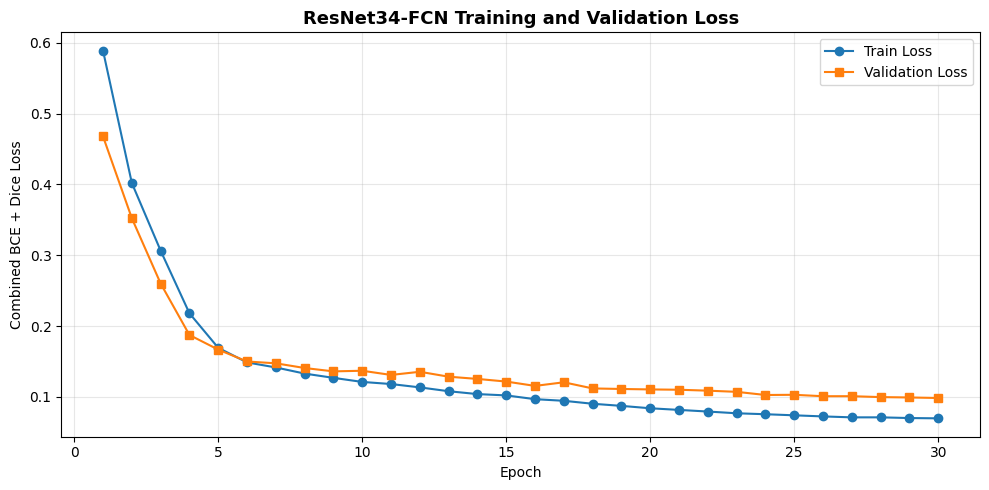


✓ Loss curve saved to: /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/resnet34_fcn_colab/results/plots/resnet34_fcn_loss_curve.png

NOTE:
• Training/validation loss is shown for optimization analysis.
• Legacy F1/IoU training curves are intentionally omitted.
• Final segmentation metrics are obtained from independent
  global validation evaluation.


In [45]:
# 9.1 Training History Visualization
#
# The legacy F1/IoU values are intentionally NOT plotted because
# the old training-loop metric path is not used for final evaluation.
#
# Training and validation LOSS values remain valid for inspecting
# optimization behavior.

import json
import pandas as pd
import matplotlib.pyplot as plt


print("=" * 75)
print("  ResNet34-FCN Training History")
print("=" * 75)


history_records = []


# ---------------------------------------------------------------------------
# 1. Prefer history stored inside the completed checkpoint
# ---------------------------------------------------------------------------

if LATEST_CHECKPOINT_PATH.exists():

    checkpoint_for_history = torch.load(
        LATEST_CHECKPOINT_PATH,
        map_location="cpu",
        weights_only=False
    )

    stored_history = checkpoint_for_history.get(
        "history",
        []
    )

    if stored_history:
        history_records = stored_history
        print(
            f"✓ Loaded {len(history_records)} history records "
            f"from latest checkpoint."
        )


# ---------------------------------------------------------------------------
# 2. Fallback to CSV if checkpoint history is unavailable
# ---------------------------------------------------------------------------

if not history_records and csv_log_path.exists():

    df_history = pd.read_csv(
        csv_log_path
    )

    print(
        f"✓ Loaded {len(df_history)} history records "
        f"from CSV."
    )

else:

    if history_records:

        df_history = pd.DataFrame(
            history_records
        )

    elif csv_log_path.exists():

        df_history = pd.read_csv(
            csv_log_path
        )

    else:

        df_history = None


# ---------------------------------------------------------------------------
# 3. Validate required loss columns
# ---------------------------------------------------------------------------

if df_history is None:

    raise FileNotFoundError(
        "No training history was found in either the "
        "latest checkpoint or training_history.csv."
    )


required_columns = {
    "epoch",
    "train_loss",
    "val_loss"
}

missing_columns = required_columns - set(
    df_history.columns
)

if missing_columns:

    raise ValueError(
        f"Training history is missing required columns: "
        f"{sorted(missing_columns)}"
    )


# ---------------------------------------------------------------------------
# 4. Plot training and validation loss
# ---------------------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(10, 5)
)

ax.plot(
    df_history["epoch"],
    df_history["train_loss"],
    marker="o",
    label="Train Loss"
)

ax.plot(
    df_history["epoch"],
    df_history["val_loss"],
    marker="s",
    label="Validation Loss"
)

ax.set_title(
    "ResNet34-FCN Training and Validation Loss",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel(
    "Epoch"
)

ax.set_ylabel(
    "Combined BCE + Dice Loss"
)

ax.grid(
    True,
    alpha=0.3
)

ax.legend()

plt.tight_layout()


# ---------------------------------------------------------------------------
# 5. Save figure
# ---------------------------------------------------------------------------

curve_path = (
    EXP_PLOTS /
    "resnet34_fcn_loss_curve.png"
)

plt.savefig(
    curve_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()


print()
print(f"✓ Loss curve saved to: {curve_path}")
print()
print("NOTE:")
print("• Training/validation loss is shown for optimization analysis.")
print("• Legacy F1/IoU training curves are intentionally omitted.")
print("• Final segmentation metrics are obtained from independent")
print("  global validation evaluation.")

## 10. Full Validation Benchmark Evaluation
Execute `scripts/evaluate.py` across all **2,367 validation samples** ($620,494,848$ total pixels) using the best saved ResNet34-FCN checkpoint.


In [46]:
# 10.1 Robust Full Validation Evaluation & Final Checkpoint Selection
#
# Both the legacy best checkpoint and the latest checkpoint are evaluated
# independently using scripts/evaluate.py.
#
# The checkpoint with the higher independently measured validation F1
# is selected as the final ResNet34-FCN model.

import json
import shutil
import subprocess
from pathlib import Path


# ---------------------------------------------------------------------------
# Evaluation directories
# ---------------------------------------------------------------------------

EVAL_ROOT = (
    EXP_EVALUATION /
    "checkpoint_selection"
)

EVAL_ROOT.mkdir(
    parents=True,
    exist_ok=True
)


# ---------------------------------------------------------------------------
# Helper: read checkpoint epoch directly
# ---------------------------------------------------------------------------

def get_checkpoint_epoch(checkpoint_path):

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    return int(
        checkpoint.get(
            "epoch",
            0
        )
    )


# ---------------------------------------------------------------------------
# Helper: independently evaluate a checkpoint
# ---------------------------------------------------------------------------

def evaluate_checkpoint(
    checkpoint_path: Path,
    output_dir: Path
):

    output_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    cmd = [
        sys.executable,
        "scripts/evaluate.py",

        "--checkpoint",
        str(checkpoint_path),

        "--model",
        "resnet34_fcn",

        "--val-dir",
        str(LOCAL_VAL_DIR),

        "--output-dir",
        str(output_dir),

        "--batch-size",
        "8",

        "--device",
        "cuda"
    ]

    print("\nRunning:")
    print(" ".join(cmd))
    print()

    subprocess.run(
        cmd,
        cwd=str(REPO_DIR),
        check=True
    )

    json_path = (
        output_dir /
        "eval_metrics.json"
    )

    if not json_path.exists():

        raise FileNotFoundError(
            f"Evaluation JSON was not created:\n{json_path}"
        )

    with open(
        json_path,
        "r",
        encoding="utf-8"
    ) as f:

        data = json.load(f)

    return data


# ---------------------------------------------------------------------------
# Checkpoint existence
# ---------------------------------------------------------------------------

if not BEST_CHECKPOINT_PATH.exists():

    raise FileNotFoundError(
        f"Missing legacy best checkpoint:\n"
        f"{BEST_CHECKPOINT_PATH}"
    )


if not LATEST_CHECKPOINT_PATH.exists():

    raise FileNotFoundError(
        f"Missing latest checkpoint:\n"
        f"{LATEST_CHECKPOINT_PATH}"
    )


# ---------------------------------------------------------------------------
# Read actual checkpoint epochs
# ---------------------------------------------------------------------------

best_epoch = get_checkpoint_epoch(
    BEST_CHECKPOINT_PATH
)

latest_epoch = get_checkpoint_epoch(
    LATEST_CHECKPOINT_PATH
)


BEST_EVAL_DIR = (
    EVAL_ROOT /
    f"legacy_best_epoch{best_epoch}"
)

LATEST_EVAL_DIR = (
    EVAL_ROOT /
    f"latest_epoch{latest_epoch}"
)


# ---------------------------------------------------------------------------
# Evaluate both checkpoints
# ---------------------------------------------------------------------------

print("=" * 75)
print("  RESNET34-FCN CHECKPOINT SELECTION")
print("=" * 75)

print(
    f"\nLegacy best checkpoint : Epoch {best_epoch}"
)

best_data = evaluate_checkpoint(
    BEST_CHECKPOINT_PATH,
    BEST_EVAL_DIR
)


print(
    f"\nLatest checkpoint      : Epoch {latest_epoch}"
)

latest_data = evaluate_checkpoint(
    LATEST_CHECKPOINT_PATH,
    LATEST_EVAL_DIR
)


# ---------------------------------------------------------------------------
# Extract independently evaluated metrics
# ---------------------------------------------------------------------------

best_metrics = best_data["metrics"]
latest_metrics = latest_data["metrics"]


# ---------------------------------------------------------------------------
# Display independent results
# ---------------------------------------------------------------------------

print("\n" + "=" * 75)
print("  INDEPENDENT VALIDATION RESULTS")
print("=" * 75)

print(
    f"Legacy best checkpoint | "
    f"Epoch {best_epoch} | "
    f"F1 = {best_metrics['f1'] * 100:.2f}% | "
    f"IoU = {best_metrics['iou'] * 100:.2f}%"
)

print(
    f"Latest checkpoint      | "
    f"Epoch {latest_epoch} | "
    f"F1 = {latest_metrics['f1'] * 100:.2f}% | "
    f"IoU = {latest_metrics['iou'] * 100:.2f}%"
)


# ---------------------------------------------------------------------------
# Select final checkpoint using independently evaluated F1
# ---------------------------------------------------------------------------

if best_metrics["f1"] >= latest_metrics["f1"]:

    selected_checkpoint = (
        BEST_CHECKPOINT_PATH
    )

    selected_data = best_data

    selected_epoch = best_epoch

    selected_label = (
        "Legacy best checkpoint"
    )

    selected_eval_source = (
        BEST_EVAL_DIR /
        "eval_metrics.json"
    )

else:

    selected_checkpoint = (
        LATEST_CHECKPOINT_PATH
    )

    selected_data = latest_data

    selected_epoch = latest_epoch

    selected_label = (
        "Latest checkpoint"
    )

    selected_eval_source = (
        LATEST_EVAL_DIR /
        "eval_metrics.json"
    )


# ---------------------------------------------------------------------------
# Stable final checkpoint paths
# ---------------------------------------------------------------------------

SELECTED_CHECKPOINT_PATH = (
    EXP_CHECKPOINTS /
    "selected_model.pth"
)

SELECTED_EVAL_JSON = (
    EVAL_ROOT /
    "selected_eval_metrics.json"
)


# ---------------------------------------------------------------------------
# Save selected checkpoint and evaluation
# ---------------------------------------------------------------------------

shutil.copy2(
    selected_checkpoint,
    SELECTED_CHECKPOINT_PATH
)

shutil.copy2(
    selected_eval_source,
    SELECTED_EVAL_JSON
)


# ---------------------------------------------------------------------------
# Final selected-model report
# ---------------------------------------------------------------------------

m = selected_data["metrics"]
cm = selected_data["confusion_matrix"]


print("\n" + "=" * 75)
print("  SELECTED FINAL RESNET34-FCN CHECKPOINT")
print("=" * 75)

print(
    f"Selection : {selected_label}"
)

print(
    f"Epoch     : {selected_epoch}"
)

print(
    f"Checkpoint: {SELECTED_CHECKPOINT_PATH}"
)

print()

print(
    f"F1 / Dice       : {m['f1'] * 100:.2f}%"
)

print(
    f"IoU             : {m['iou'] * 100:.2f}%"
)

print(
    f"Precision       : {m['precision'] * 100:.2f}%"
)

print(
    f"Recall          : {m['recall'] * 100:.2f}%"
)

print(
    f"Pixel Accuracy  : {m['accuracy'] * 100:.2f}%"
)

print()

print(
    f"True Positives  : {cm['TP']:,}"
)

print(
    f"False Positives : {cm['FP']:,}"
)

print(
    f"False Negatives : {cm['FN']:,}"
)

print(
    f"True Negatives  : {cm['TN']:,}"
)

print("=" * 75)

print()
print(
    "✓ Final checkpoint selected using independently evaluated "
    "global validation F1."
)

print(
    "✓ Epoch number was read directly from the checkpoint."
)

print(
    "✓ Final checkpoint copied to selected_model.pth."
)

print(
    f"✓ Evaluation JSON saved to: {SELECTED_EVAL_JSON}"
)

  RESNET34-FCN CHECKPOINT SELECTION

Legacy best checkpoint : Epoch 27

Running:
/usr/bin/python3 scripts/evaluate.py --checkpoint /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/resnet34_fcn_colab/checkpoints/best_model.pth --model resnet34_fcn --val-dir /content/glid_clean/val --output-dir /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/resnet34_fcn_colab/results/evaluation/checkpoint_selection/legacy_best_epoch27 --batch-size 8 --device cuda


Latest checkpoint      : Epoch 30

Running:
/usr/bin/python3 scripts/evaluate.py --checkpoint /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/resnet34_fcn_colab/checkpoints/latest_model.pth --model resnet34_fcn --val-dir /content/glid_clean/val --output-dir /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/resnet34_fcn_colab/results/evaluation/checkpoint_selection/latest_epoch30 --batch-size 8 --device cuda


  INDEPENDENT VALIDATION RESULTS
Legacy best checkpoint | Epoch 27 | F1 = 93.10% | IoU

## 11. DeepLabV3+ vs. ResNet34-FCN Comparative Benchmark

Generate a side-by-side benchmark table comparing the **DeepLabV3+ advanced model** (ResNet-50 + ASPP) against the **ResNet34-FCN baseline** on the identical validation split ($N=2,367$).

> **Academic Rigor & Fairness Notice**:
> - Both architectures were trained and evaluated on the exact same official GLID validation split ($2,367$ samples, $620,494,848$ total pixels).
> - Both architectures use the exact same input standardization (ImageNet $\mu, \sigma$), binary decision threshold ($0.5$), and global confusion matrix metric formulation.
> - All reported numbers represent **validation metrics**, not independent unannotated field test scenes.


In [47]:
# 11.1 ResNet34-FCN vs DeepLabV3+ — Direct Same-Split Comparison

import json
from pathlib import Path
import torch


# ---------------------------------------------------------------------------
# DeepLabV3+ checkpoint from the verified previous notebook
# ---------------------------------------------------------------------------

DEEPLAB_CHECKPOINT_PATH = Path(
    "/content/drive/MyDrive/"
    "Glacial_Lake_Segmentation/"
    "training/deeplabv3plus_fast/"
    "checkpoints/best_amp_model.pth"
)

if not DEEPLAB_CHECKPOINT_PATH.exists():

    raise FileNotFoundError(
        f"DeepLabV3+ checkpoint not found:\n"
        f"{DEEPLAB_CHECKPOINT_PATH}"
    )


# ---------------------------------------------------------------------------
# Shared metric function
# ---------------------------------------------------------------------------

def global_metrics_from_logits(
    logits,
    masks,
    counts=None,
    threshold=0.5
):

    probs = torch.sigmoid(
        logits.float()
    )

    preds = probs >= threshold
    truth = masks >= 0.5

    tp = torch.logical_and(
        preds,
        truth
    ).sum().item()

    fp = torch.logical_and(
        preds,
        ~truth
    ).sum().item()

    fn = torch.logical_and(
        ~preds,
        truth
    ).sum().item()

    tn = torch.logical_and(
        ~preds,
        ~truth
    ).sum().item()

    if counts is None:

        counts = {
            "TP": 0,
            "FP": 0,
            "FN": 0,
            "TN": 0
        }

    counts["TP"] += tp
    counts["FP"] += fp
    counts["FN"] += fn
    counts["TN"] += tn

    return counts


def metrics_from_cm(cm):

    tp = cm["TP"]
    fp = cm["FP"]
    fn = cm["FN"]
    tn = cm["TN"]

    eps = 1e-8

    return {
        "f1":
            (2 * tp + eps) /
            (2 * tp + fp + fn + eps),

        "iou":
            (tp + eps) /
            (tp + fp + fn + eps),

        "precision":
            (tp + eps) /
            (tp + fp + eps),

        "recall":
            (tp + eps) /
            (tp + fn + eps),

        "accuracy":
            (tp + tn) /
            (tp + tn + fp + fn + eps)
    }


# ---------------------------------------------------------------------------
# Load selected ResNet34-FCN evaluation
# ---------------------------------------------------------------------------

with open(
    SELECTED_EVAL_JSON,
    "r",
    encoding="utf-8"
) as f:

    resnet_eval = json.load(f)

resnet_metrics = resnet_eval["metrics"]


# ---------------------------------------------------------------------------
# Load DeepLabV3+
# ---------------------------------------------------------------------------

print("=" * 75)
print("  Loading DeepLabV3+ checkpoint")
print("=" * 75)

deeplab_cfg = {
    "model": {
        "name": "deeplabv3plus",
        "pretrained": False,
        "num_classes": 1,
        "freeze_encoder": False,
        "aspp_dilations": [6, 12, 18],
    }
}

deeplab_model = build_model(
    deeplab_cfg
).to(device)

deeplab_checkpoint = torch.load(
    DEEPLAB_CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

deeplab_model.load_state_dict(
    deeplab_checkpoint["model_state_dict"]
)

deeplab_model.eval()

deeplab_epoch = deeplab_checkpoint.get(
    "epoch",
    "unknown"
)

print(
    f"DeepLabV3+ checkpoint epoch: "
    f"{deeplab_epoch}"
)


# ---------------------------------------------------------------------------
# Evaluate DeepLabV3+ on the SAME validation loader
# ---------------------------------------------------------------------------

deeplab_cm = {
    "TP": 0,
    "FP": 0,
    "FN": 0,
    "TN": 0
}

print("\nEvaluating DeepLabV3+ on the same 2,367 validation samples...")

with torch.no_grad():

    for images, masks in tqdm(
        val_loader,
        desc="DeepLabV3+ validation"
    ):

        images = images.to(
            device,
            non_blocking=True,
            memory_format=torch.channels_last
        )

        masks = masks.to(
            device,
            non_blocking=True
        )

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):

            logits = deeplab_model(images)

        deeplab_cm = global_metrics_from_logits(
            logits,
            masks,
            deeplab_cm
        )


deeplab_metrics = metrics_from_cm(
    deeplab_cm
)


# ---------------------------------------------------------------------------
# Parameter counts
# ---------------------------------------------------------------------------

resnet_model_for_count = build_model({
    "model": {
        "name": "resnet34_fcn",
        "pretrained": False,
        "num_classes": 1,
        "freeze_encoder": False
    }
})

resnet_params = sum(
    p.numel()
    for p in resnet_model_for_count.parameters()
)

deeplab_params = sum(
    p.numel()
    for p in deeplab_model.parameters()
)


# ---------------------------------------------------------------------------
# Comparison table
# ---------------------------------------------------------------------------

comparison = {
    "validation_samples": 2367,

    "ResNet34-FCN": {
        "epoch": resnet_eval.get(
            "checkpoint_epoch",
            "selected"
        ),
        "parameters": resnet_params,
        "f1": resnet_metrics["f1"],
        "iou": resnet_metrics["iou"],
        "precision": resnet_metrics["precision"],
        "recall": resnet_metrics["recall"],
        "accuracy": resnet_metrics["accuracy"],
        "hardware": "Tesla T4 / CUDA + AMP"
    },

    "DeepLabV3+": {
        "epoch": deeplab_epoch,
        "parameters": deeplab_params,
        "f1": deeplab_metrics["f1"],
        "iou": deeplab_metrics["iou"],
        "precision": deeplab_metrics["precision"],
        "recall": deeplab_metrics["recall"],
        "accuracy": deeplab_metrics["accuracy"],
        "hardware": "Tesla T4 / CUDA + AMP"
    }
}


# ---------------------------------------------------------------------------
# Save machine-readable comparison
# ---------------------------------------------------------------------------

EXP_COMPARISON.mkdir(
    parents=True,
    exist_ok=True
)

comparison_json = (
    EXP_COMPARISON /
    "resnet34_vs_deeplabv3_comparison.json"
)

with open(
    comparison_json,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        comparison,
        f,
        indent=2
    )


# ---------------------------------------------------------------------------
# Save Markdown table
# ---------------------------------------------------------------------------

table = f"""
# ResNet34-FCN vs DeepLabV3+ Validation Comparison

**Validation samples:** 2,367
**Threshold:** 0.5
**Evaluation:** Global pixel-level confusion matrix

| Metric | ResNet34-FCN | DeepLabV3+ |
|---|---:|---:|
| Epoch | {comparison["ResNet34-FCN"]["epoch"]} | {comparison["DeepLabV3+"]["epoch"]} |
| Parameters | {resnet_params:,} | {deeplab_params:,} |
| F1 / Dice | {resnet_metrics["f1"]*100:.2f}% | {deeplab_metrics["f1"]*100:.2f}% |
| IoU | {resnet_metrics["iou"]*100:.2f}% | {deeplab_metrics["iou"]*100:.2f}% |
| Precision | {resnet_metrics["precision"]*100:.2f}% | {deeplab_metrics["precision"]*100:.2f}% |
| Recall | {resnet_metrics["recall"]*100:.2f}% | {deeplab_metrics["recall"]*100:.2f}% |
| Pixel Accuracy | {resnet_metrics["accuracy"]*100:.2f}% | {deeplab_metrics["accuracy"]*100:.2f}% |
| Training Hardware | T4 / CUDA + AMP | T4 / CUDA + AMP |

> These are validation metrics, not independent test-set results.
"""

comparison_md = (
    EXP_COMPARISON /
    "comparison_table.md"
)

comparison_md.write_text(
    table,
    encoding="utf-8"
)


# ---------------------------------------------------------------------------
# Print final result
# ---------------------------------------------------------------------------

print("\n" + "=" * 75)
print("  FINAL ARCHITECTURAL COMPARISON")
print("=" * 75)

print(table)

print(f"\n✓ JSON saved: {comparison_json}")
print(f"✓ Markdown saved: {comparison_md}")

  Loading DeepLabV3+ checkpoint
DeepLabV3+ checkpoint epoch: 26

Evaluating DeepLabV3+ on the same 2,367 validation samples...


DeepLabV3+ validation:   0%|          | 0/296 [00:00<?, ?it/s]


  FINAL ARCHITECTURAL COMPARISON

# ResNet34-FCN vs DeepLabV3+ Validation Comparison

**Validation samples:** 2,367  
**Threshold:** 0.5  
**Evaluation:** Global pixel-level confusion matrix

| Metric | ResNet34-FCN | DeepLabV3+ |
|---|---:|---:|
| Epoch | selected | 26 |
| Parameters | 24,079,153 | 40,347,041 |
| F1 / Dice | 93.27% | 93.97% |
| IoU | 87.39% | 88.62% |
| Precision | 94.21% | 95.61% |
| Recall | 92.35% | 92.38% |
| Pixel Accuracy | 99.70% | 99.73% |
| Training Hardware | T4 / CUDA + AMP | T4 / CUDA + AMP |

> These are validation metrics, not independent test-set results.


✓ JSON saved: /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/resnet34_fcn_colab/comparison/resnet34_vs_deeplabv3_comparison.json
✓ Markdown saved: /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/resnet34_fcn_colab/comparison/comparison_table.md


## 12. Qualitative Visual Predictions
Generate 4-panel visual comparison figures (Satellite RGB, Ground Truth, ResNet34-FCN Prediction, Probability Heatmap) for representative validation scenes.


✓ Loaded selected ResNet34-FCN checkpoint (epoch 30)


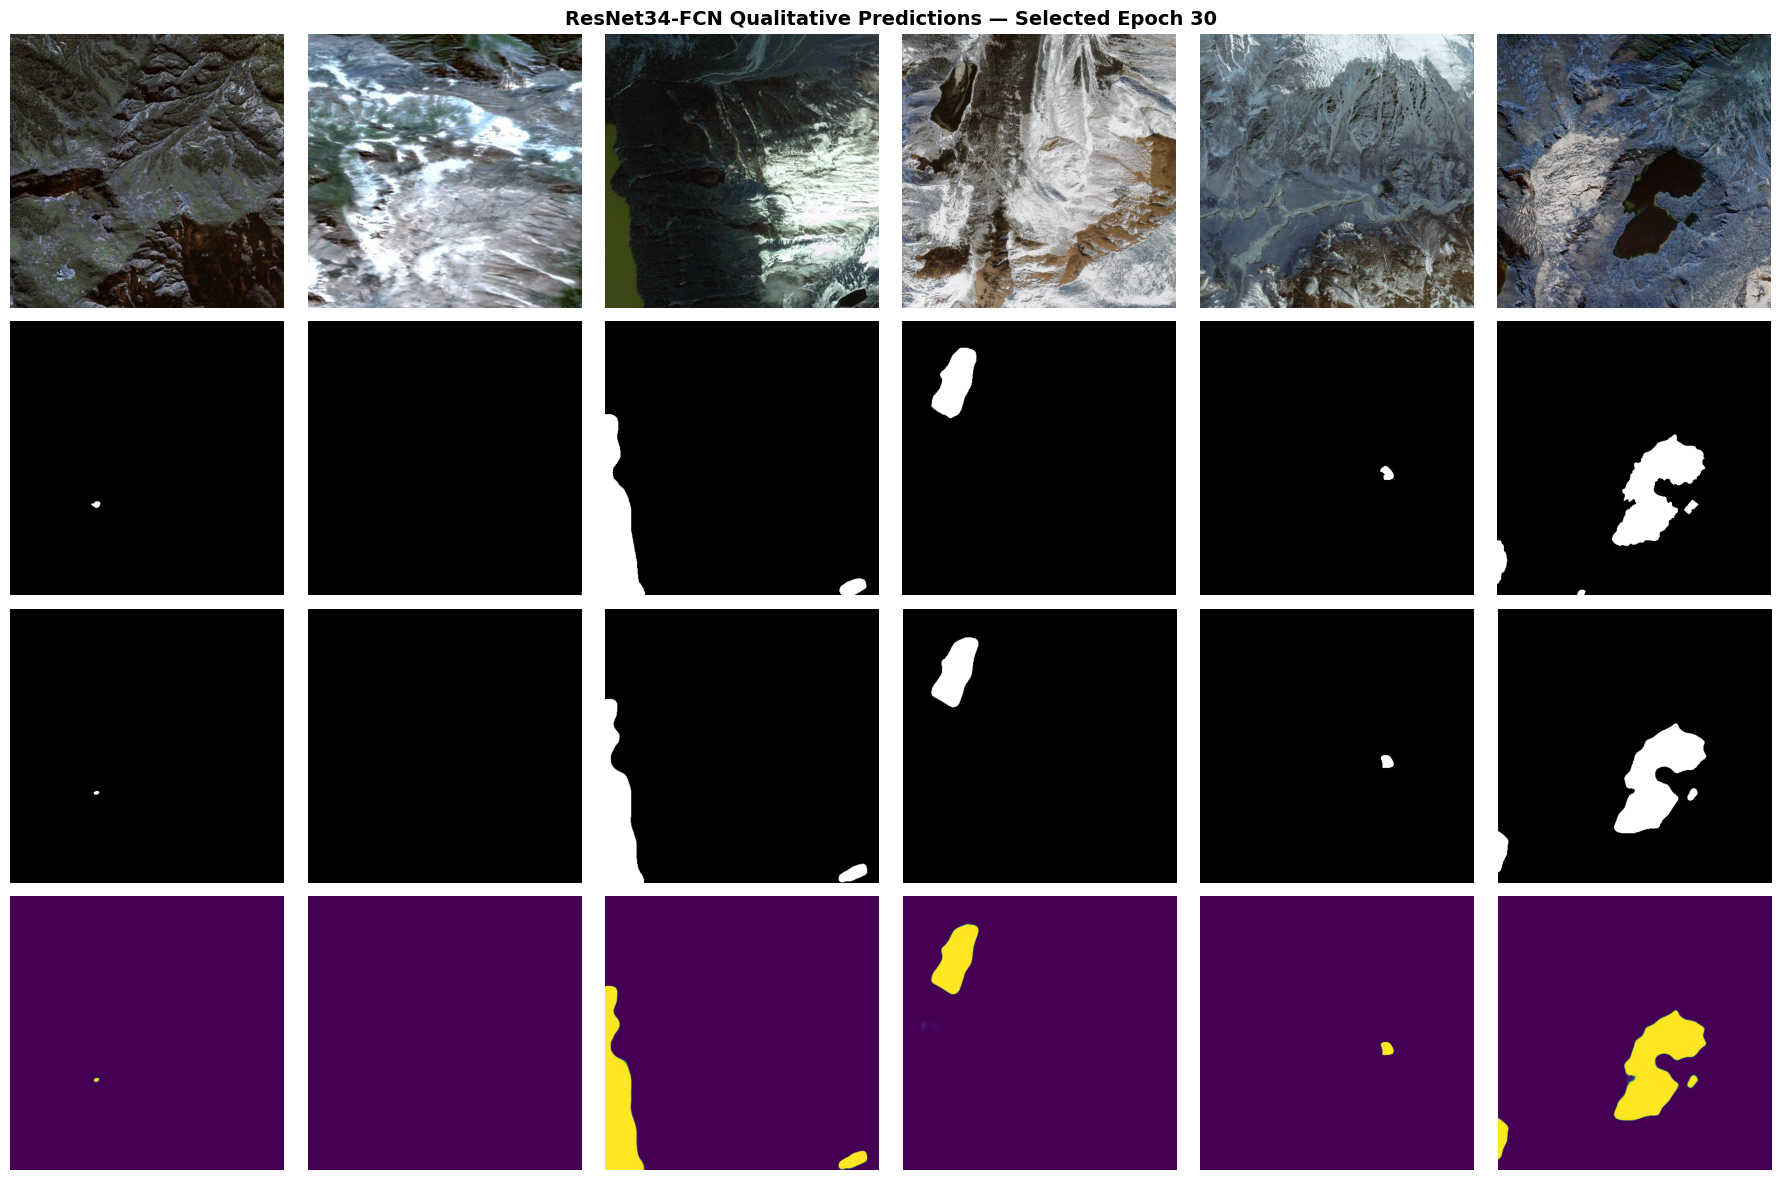

✓ Qualitative predictions saved to: /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/resnet34_fcn_colab/results/predictions/selected_model_validation_predictions.png


In [48]:
# 12.1 Qualitative Predictions from the Selected Final Checkpoint

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import DataLoader


if not SELECTED_CHECKPOINT_PATH.exists():

    raise FileNotFoundError(
        f"Selected checkpoint not found:\n"
        f"{SELECTED_CHECKPOINT_PATH}\n"
        "Run Cell 10.1 first."
    )


# ---------------------------------------------------------------------------
# Load selected checkpoint into a fresh model
# ---------------------------------------------------------------------------

selected_model = build_model({
    "model": {
        "name": "resnet34_fcn",
        "pretrained": False,
        "num_classes": 1,
        "freeze_encoder": False
    }
}).to(device)

selected_checkpoint = torch.load(
    SELECTED_CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

selected_model.load_state_dict(
    selected_checkpoint["model_state_dict"]
)

selected_model.eval()

selected_epoch = selected_checkpoint.get(
    "epoch",
    "unknown"
)

print(
    f"✓ Loaded selected ResNet34-FCN checkpoint "
    f"(epoch {selected_epoch})"
)


# ---------------------------------------------------------------------------
# Load validation samples
# ---------------------------------------------------------------------------

vis_loader = DataLoader(
    val_ds,
    batch_size=6,
    shuffle=False
)

imgs, msks = next(
    iter(vis_loader)
)


# ---------------------------------------------------------------------------
# Prediction
# ---------------------------------------------------------------------------

with torch.no_grad():

    x = imgs.to(
        device,
        memory_format=torch.channels_last
    )

    with torch.autocast(
        device_type="cuda",
        dtype=torch.float16
    ):

        logits = selected_model(x)

        probs = torch.sigmoid(
            logits
        )

        preds = (
            probs >= 0.5
        ).float()


# ---------------------------------------------------------------------------
# Convert normalized RGB back to display space
# ---------------------------------------------------------------------------

imgs_np = (
    imgs
    .permute(0, 2, 3, 1)
    .cpu()
    .numpy()
)

mean = np.array(
    [0.485, 0.456, 0.406]
)

std = np.array(
    [0.229, 0.224, 0.225]
)

imgs_np = np.clip(
    imgs_np * std + mean,
    0.0,
    1.0
)

gt_np = (
    msks
    .squeeze(1)
    .cpu()
    .numpy()
)

pred_np = (
    preds
    .squeeze(1)
    .cpu()
    .numpy()
)

prob_np = (
    probs
    .squeeze(1)
    .float()
    .cpu()
    .numpy()
)


# ---------------------------------------------------------------------------
# Figure
# ---------------------------------------------------------------------------

fig, axes = plt.subplots(
    4,
    6,
    figsize=(18, 12)
)

for i in range(6):

    # RGB
    axes[0, i].imshow(
        imgs_np[i]
    )

    axes[0, i].axis("off")

    if i == 0:
        axes[0, i].set_ylabel(
            "Satellite RGB",
            fontsize=10,
            fontweight="bold"
        )


    # Ground truth
    axes[1, i].imshow(
        gt_np[i],
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[1, i].axis("off")

    if i == 0:
        axes[1, i].set_ylabel(
            "Ground Truth",
            fontsize=10,
            fontweight="bold"
        )


    # Prediction
    axes[2, i].imshow(
        pred_np[i],
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[2, i].axis("off")

    if i == 0:
        axes[2, i].set_ylabel(
            "Predicted Mask",
            fontsize=10,
            fontweight="bold"
        )


    # Probability
    axes[3, i].imshow(
        prob_np[i],
        cmap="viridis",
        vmin=0,
        vmax=1
    )

    axes[3, i].axis("off")

    if i == 0:
        axes[3, i].set_ylabel(
            "Lake Probability",
            fontsize=10,
            fontweight="bold"
        )


plt.suptitle(
    f"ResNet34-FCN Qualitative Predictions — Selected Epoch {selected_epoch}",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

vis_save_path = (
    EXP_PREDICTIONS /
    "selected_model_validation_predictions.png"
)

plt.savefig(
    vis_save_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print(
    f"✓ Qualitative predictions saved to: "
    f"{vis_save_path}"
)